<a href="https://colab.research.google.com/github/jisukim2003/SEAWATER/blob/main/SEAWATER_v1.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# SEAWATER v1 — Heterostructure Nested Learning for Alkaline Seawater OER

This notebook implements a small-data, heterostructure-aware discovery pipeline for **Fe–Co–Ni core / Ti–Cr–Mo–W shell** electrocatalysts.

### Scientific design

- **Experimental training set:** 30 catalysts in `SEAWATER/database/SEAWATER_train.csv`.
- **Spectroscopic state:** `[O_lattice, O_vacancy, raman_1, raman_2]`.
  - O 1s is represented by the measured lattice-oxygen and vacancy-related fractions; the surface fraction is reconstructed as `1 - O_lattice - O_vacancy`.
  - Raman raw spectra are loaded from `SEAWATER/database/raman/S01.csv ... S30.csv`, preprocessed over 120–1000 cm⁻¹, decomposed by rank-3 NMF, and represented as `raman_1=C1`, `raman_2=C2`, with `C3=1-C1-C2`.
  - CV fits Raman NMF **inside the training fold**; the held-out spectrum is transformed by the training-fold NMF basis.
- **Targets:** overpotential, stability, and corrosion.
  - Corrosion is retained at the seven-metal level (`Fe, Co, Ni, Ti, Cr, Mo, W`).
  - Core, shell, and total corrosion are derived with the **as-prepared metal molar ratios in the seven composition columns as weights**.
  - Metal-specific corrosion for an absent metal is masked, not treated as zero corrosion.
- **Material representation:** core, shell, and explicit low-rank core–shell interface channels. No hypothetical unit cell or atomic-neighbor graph is imposed.
- **Heterostructure Nested Learning (HNL):** core, interface, and shell learners have distinct context flows and, when Nested Learning is ON, data-selected update frequencies. The synchronous control uses the **identical architecture and parameterization** but updates all three modules every optimization step.
- **Validation:** outer `5CV`, `10CV`, or `LOOCV`; inner `5CV`, `10CV`, or `LOOCV` selects update clocks and refit epochs without touching the outer test fold.
- **Final screening:** full-data seed ensemble screens the complete 0.1-grid `SEAWATER_screen.csv` (18,876 candidates). No RL/generative iterative search is used.
- **Interpretation:** target-specific clock frequencies, core/interface/shell/spectroscopy contributions, simplex-preserving metal substitutions, effective 3×4 core–shell interaction matrices, spectroscopy–property associations, and metal-resolved corrosion.

### Nested Learning terminology

Google Research / NeurIPS 2025 describes Nested Learning as a view of a model as interconnected multi-level/parallel optimization problems with distinct **context flows** and **update rates**. This notebook implements a domain-specific HNL instance: core, interface, and shell are separate optimization modules with distinct physical inputs; their update frequencies are selected by inner validation. It does **not** reproduce the language-model-specific Hope architecture.

References:
- A. Behrouz *et al.*, “Nested Learning: The Illusion of Deep Learning Architectures,” NeurIPS 2025.
- Google Research, “Introducing Nested Learning: A new ML paradigm for continual learning,” 2025.

> **Important:** the currently supplied spectroscopy/electrochemistry/corrosion values are placeholders. Use `PLACEHOLDER_MODE=True` only for pipeline testing. Set it to `False` for scientific runs after replacing them with experimental values.

In [ ]:
# ============================================================
# 0. Google Drive mount
# ============================================================
try:
    from google.colab import drive
    drive.mount('/content/drive')
except Exception as e:
    print(f"Google Drive mount skipped (non-Colab environment or already unavailable): {e}")

Mounted at /content/drive


In [ ]:
# ============================================================
# 1. USER CONFIGURATION
# ============================================================

BASE_DIR = "/content/drive/MyDrive/Colab Notebooks/SEAWATER"
VERSION = "v1"

TRAIN_CSV_PATH = f"{BASE_DIR}/database/SEAWATER_train.csv"
SCREEN_CSV_PATH = f"{BASE_DIR}/database/SEAWATER_screen.csv"
SCREEN_CLUSTER_CSV_PATH = f"{BASE_DIR}/database/SEAWATER_screen_cluster.csv"  # reference only; not used for v1 screening
RAMAN_DIR = f"{BASE_DIR}/database/raman"

# ----------------------------
# Run mode
# ----------------------------
# "single": run only the variant selected by NESTED_LEARNING
# "compare": run both hierarchical (synchronous control) and nested using identical folds/seeds
RUN_MODE = "compare"                 # "single" or "compare"
NESTED_LEARNING = True               # used only when RUN_MODE == "single"

# ----------------------------
# Cross-validation
# ----------------------------
CV_TYPE = "5CV"                      # "5CV", "10CV", "LOOCV"
INNER_CV_TYPE = "5CV"               # "5CV", "10CV", "LOOCV"
CV_SPLIT_SEED = 0
SEEDS = list(range(10))               # seed ensemble for outer CV and full-data models
CLOCK_SEARCH_SEED = 0            # one fixed seed for inner model-selection; avoids multiplying search cost by ensemble size

# ----------------------------
# Nested Learning update clocks
# ----------------------------
# A clock of k means that the corresponding physical module is updated every k full-batch epochs.
# Hierarchical control always uses (1, 1, 1).
NESTED_CLOCKS = [1, 4, 16]
CLOCK_ORDER = ("core", "interface", "shell")

# ----------------------------
# Small-data architecture
# ----------------------------
HIDDEN_DIM = 4
INTERFACE_RANK = 2
LEARNING_RATE = 3e-3
WEIGHT_DECAY = 1e-3
MAX_INNER_EPOCHS = 800
INNER_PATIENCE = 100
MIN_INNER_EPOCHS = 120
MAX_REFIT_EPOCHS = 1600
GRAD_CLIP_NORM = 5.0

# ----------------------------
# Spectroscopy generator
# ----------------------------
SPEC_LEARNING_RATE = 3e-3
SPEC_WEIGHT_DECAY = 1e-3
SPEC_MAX_INNER_EPOCHS = 1000
SPEC_INNER_PATIENCE = 120
SPEC_MIN_INNER_EPOCHS = 150
SPEC_MAX_REFIT_EPOCHS = 1800

# ----------------------------
# Raman preprocessing / NMF
# ----------------------------
USE_RAW_RAMAN = True
RAMAN_REQUIRE_ALL = True              # scientific run: require S01.csv ... S30.csv
RAMAN_ALLOW_CSV_FALLBACK = True       # useful only for placeholder/smoke-test runs
RAMAN_MIN_CM = 120.0
RAMAN_MAX_CM = 1000.0
RAMAN_GRID_STEP_CM = 2.0
RAMAN_N_COMPONENTS = 3
RAMAN_SAVGOL_WINDOW = 11
RAMAN_SAVGOL_POLYORDER = 3
RAMAN_DESPIKE_KERNEL = 5
RAMAN_DESPIKE_Z = 8.0
RAMAN_ALS_LAMBDA = 1e6
RAMAN_ALS_P = 0.01
RAMAN_ALS_NITER = 12
RAMAN_NMF_MAX_ITER = 5000
RAMAN_NMF_SEED = 0

# ----------------------------
# Data validation
# ----------------------------
PLACEHOLDER_MODE = False               # CHANGE TO False after real experimental values are inserted
SIMPLEX_TOL = 1e-6
PRESENT_EPS = 1e-10

# ----------------------------
# Corrosion loss hierarchy
# ----------------------------
# Top-level task weights remain activity : stability : corrosion = 1 : 1 : 1.
CORROSION_LOSS_WEIGHTS = {
    "total": 0.50,
    "region": 0.20,                  # equally divided between core and shell
    "metal": 0.30,                   # average across observed metal-specific targets; absent metals are masked
}

# ----------------------------
# Optional conventional baselines / interpretation
# ----------------------------
RUN_CONVENTIONAL_BASELINES = True
BASELINE_MODELS = ["ridge", "pls", "gpr", "extratrees"]
RUN_SCREENING = True
RUN_INTERPRETATION = True
N_PAIRED_BOOTSTRAP = 5000

# ----------------------------
# Runtime / checkpointing
# ----------------------------
RESUME = True                         # completed compatible checkpoints are reused
ALWAYS_SAVE_CHECKPOINTS = True        # intentionally not user-disableable in v1
VERBOSE_INNER_SEARCH = False

print("Configuration loaded.")
print("RUN_MODE:", RUN_MODE)
print("CV_TYPE / INNER_CV_TYPE:", CV_TYPE, "/", INNER_CV_TYPE)
print("SEEDS:", SEEDS)

Configuration loaded.
RUN_MODE: compare
CV_TYPE / INNER_CV_TYPE: 5CV / 5CV
SEEDS: [0, 1, 2, 3, 4, 5, 6, 7, 8, 9]


In [ ]:
# ============================================================
# 2. Imports, reproducibility, paths, configuration signature
# ============================================================
import os
import json
import math
import glob
import time
import random
import hashlib
import itertools
import warnings
from pathlib import Path
from copy import deepcopy

import numpy as np
import pandas as pd
import joblib
import matplotlib.pyplot as plt
from IPython.display import display

from scipy import sparse
from scipy.sparse.linalg import spsolve
from scipy.signal import savgol_filter, medfilt
from scipy.stats import spearmanr, wilcoxon

from sklearn.decomposition import NMF
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import KFold, LeaveOneOut
from sklearn.metrics import r2_score, mean_squared_error, mean_absolute_error
from sklearn.linear_model import Ridge
from sklearn.cross_decomposition import PLSRegression
from sklearn.gaussian_process import GaussianProcessRegressor
from sklearn.gaussian_process.kernels import ConstantKernel, Matern, WhiteKernel
from sklearn.ensemble import ExtraTreesRegressor

import torch
import torch.nn as nn
import torch.nn.functional as F

warnings.filterwarnings("ignore")

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("PyTorch device:", DEVICE)
if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))

NAME_COL = "name"
CORE_ELEMENTS = ["Fe", "Co", "Ni"]
SHELL_ELEMENTS = ["Ti", "Cr", "Mo", "W"]
METALS = CORE_ELEMENTS + SHELL_ELEMENTS
CORE_COLS = [f"core_{e}" for e in CORE_ELEMENTS]
SHELL_COLS = [f"shell_{e}" for e in SHELL_ELEMENTS]
COMP_COLS = CORE_COLS + SHELL_COLS
SPEC_COLS = ["O_lattice", "O_vacancy", "raman_1", "raman_2"]
PRIMARY_TARGETS = ["overpotential", "stability", "corrosion_total"]
CORROSION_COLS = [f"corrosion_{e}" for e in METALS]
REQUIRED_TRAIN_COLS = [NAME_COL] + COMP_COLS + SPEC_COLS + ["overpotential", "stability"] + CORROSION_COLS
REQUIRED_SCREEN_COLS = [NAME_COL] + COMP_COLS

OBJECTIVE_DIRECTIONS = {
    "overpotential": "min",
    "stability": "max",
    "corrosion_total": "min",
}

ELEMENT_PROPERTIES = {
    "Fe": {"valence": 8,  "ionization": 7.902, "electronegativity": 1.83, "radius": 132},
    "Co": {"valence": 9,  "ionization": 7.881, "electronegativity": 1.88, "radius": 126},
    "Ni": {"valence": 10, "ionization": 7.640, "electronegativity": 1.91, "radius": 124},
    "Ti": {"valence": 4,  "ionization": 6.828, "electronegativity": 1.54, "radius": 160},
    "Cr": {"valence": 6,  "ionization": 6.766, "electronegativity": 1.66, "radius": 139},
    "Mo": {"valence": 6,  "ionization": 7.092, "electronegativity": 2.16, "radius": 154},
    "W":  {"valence": 6,  "ionization": 7.864, "electronegativity": 2.36, "radius": 162},
}
PROP_NAMES = ["valence", "ionization", "electronegativity", "radius"]

TRAIN_ROOT = Path(BASE_DIR) / "train" / VERSION
SCREEN_ROOT = Path(BASE_DIR) / "screen" / VERSION
SHARED_ROOT = TRAIN_ROOT / "shared"
BASELINES_ROOT = TRAIN_ROOT / "baselines"
TRAIN_COMPARISON_ROOT = TRAIN_ROOT / "comparison"
SCREEN_COMPARISON_ROOT = SCREEN_ROOT / "comparison"

for p in [TRAIN_ROOT, SCREEN_ROOT, SHARED_ROOT, BASELINES_ROOT, TRAIN_COMPARISON_ROOT, SCREEN_COMPARISON_ROOT]:
    p.mkdir(parents=True, exist_ok=True)


def set_global_seed(seed: int):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)


def to_jsonable(x):
    if isinstance(x, (np.integer,)): return int(x)
    if isinstance(x, (np.floating,)): return float(x)
    if isinstance(x, np.ndarray): return x.tolist()
    if isinstance(x, Path): return str(x)
    if isinstance(x, tuple): return list(x)
    return x


def save_json(obj, path):
    path = Path(path)
    path.parent.mkdir(parents=True, exist_ok=True)
    with open(path, "w", encoding="utf-8") as f:
        json.dump(obj, f, indent=2, default=to_jsonable)


CONFIG_FOR_HASH = {
    "version": VERSION,
    "cv": CV_TYPE,
    "inner_cv": INNER_CV_TYPE,
    "cv_split_seed": CV_SPLIT_SEED,
    "ensemble_seeds": SEEDS,
    "clock_search_seed": CLOCK_SEARCH_SEED,
    "clocks": NESTED_CLOCKS,
    "hidden": HIDDEN_DIM,
    "rank": INTERFACE_RANK,
    "lr": LEARNING_RATE,
    "wd": WEIGHT_DECAY,
    "max_inner_epochs": MAX_INNER_EPOCHS,
    "inner_patience": INNER_PATIENCE,
    "min_inner_epochs": MIN_INNER_EPOCHS,
    "max_refit_epochs": MAX_REFIT_EPOCHS,
    "spec_lr": SPEC_LEARNING_RATE,
    "spec_wd": SPEC_WEIGHT_DECAY,
    "spec_max_inner_epochs": SPEC_MAX_INNER_EPOCHS,
    "spec_inner_patience": SPEC_INNER_PATIENCE,
    "spec_min_inner_epochs": SPEC_MIN_INNER_EPOCHS,
    "spec_max_refit_epochs": SPEC_MAX_REFIT_EPOCHS,
    "raman_range": [RAMAN_MIN_CM, RAMAN_MAX_CM],
    "raman_step": RAMAN_GRID_STEP_CM,
    "raman_components": RAMAN_N_COMPONENTS,
    "raman_savgol": [RAMAN_SAVGOL_WINDOW, RAMAN_SAVGOL_POLYORDER],
    "raman_despike": [RAMAN_DESPIKE_KERNEL, RAMAN_DESPIKE_Z],
    "raman_als": [RAMAN_ALS_LAMBDA, RAMAN_ALS_P, RAMAN_ALS_NITER],
    "raman_nmf": [RAMAN_NMF_MAX_ITER, RAMAN_NMF_SEED],
    "use_raw_raman": USE_RAW_RAMAN,
    "placeholder_mode": PLACEHOLDER_MODE,
    "corrosion_loss_weights": CORROSION_LOSS_WEIGHTS,
}

CONFIG_HASH = hashlib.sha256(json.dumps(CONFIG_FOR_HASH, sort_keys=True).encode()).hexdigest()[:12]
print("CONFIG_HASH:", CONFIG_HASH)

save_json(CONFIG_FOR_HASH, SHARED_ROOT / "config_signature.json")

PyTorch device: cuda
GPU: Tesla T4
CONFIG_HASH: 86726e5438c1


In [ ]:
# ============================================================
# 3. Load and validate train/screen tables
# ============================================================

def require_columns(df, cols, label):
    missing = [c for c in cols if c not in df.columns]
    if missing:
        raise ValueError(f"{label} is missing required columns: {missing}")


def numericize(df, cols):
    out = df.copy()
    for c in cols:
        out[c] = pd.to_numeric(out[c], errors="coerce")
    return out


def project_two_to_three_simplex(a, b, strict=True, label="simplex"):
    a = np.asarray(a, dtype=float).copy()
    b = np.asarray(b, dtype=float).copy()
    if strict:
        if np.any(~np.isfinite(a)) or np.any(~np.isfinite(b)):
            raise ValueError(f"{label}: non-finite values detected.")
        if np.any(a < -SIMPLEX_TOL) or np.any(b < -SIMPLEX_TOL):
            raise ValueError(f"{label}: negative fractions detected.")
        if np.any(a + b > 1.0 + SIMPLEX_TOL):
            bad = np.where(a + b > 1.0 + SIMPLEX_TOL)[0].tolist()
            raise ValueError(f"{label}: first two fractions exceed 1 at rows {bad}.")
        a = np.clip(a, 0.0, 1.0)
        b = np.clip(b, 0.0, 1.0)
        c = np.clip(1.0 - a - b, 0.0, 1.0)
        s = a + b + c
        return np.column_stack([a / s, b / s, c / s])

    # Placeholder/smoke-test projection only. Real scientific data should use strict mode.
    a = np.nan_to_num(a, nan=0.0, posinf=1.0, neginf=0.0)
    b = np.nan_to_num(b, nan=0.0, posinf=1.0, neginf=0.0)
    a = np.clip(a, 0.0, None)
    b = np.clip(b, 0.0, None)
    c = np.clip(1.0 - a - b, 0.0, None)
    arr = np.column_stack([a, b, c])
    sums = arr.sum(axis=1, keepdims=True)
    zero = sums[:, 0] <= 1e-12
    arr[zero] = np.array([1/3, 1/3, 1/3])
    sums = arr.sum(axis=1, keepdims=True)
    return arr / sums


train_df = pd.read_csv(TRAIN_CSV_PATH)
screen_df = pd.read_csv(SCREEN_CSV_PATH)
require_columns(train_df, REQUIRED_TRAIN_COLS, "SEAWATER_train.csv")
require_columns(screen_df, REQUIRED_SCREEN_COLS, "SEAWATER_screen.csv")

train_df = numericize(train_df, COMP_COLS + SPEC_COLS + ["overpotential", "stability"] + CORROSION_COLS)
screen_df = numericize(screen_df, COMP_COLS)

if train_df[NAME_COL].duplicated().any():
    raise ValueError("SEAWATER_train.csv contains duplicated sample names.")
if screen_df[NAME_COL].duplicated().any():
    raise ValueError("SEAWATER_screen.csv contains duplicated candidate names.")
if len(train_df) != 30:
    print(f"WARNING: expected 30 training samples, found {len(train_df)}.")
if len(screen_df) != 18876:
    print(f"WARNING: expected 18,876 screen candidates, found {len(screen_df)}.")

for label, df in [("train", train_df), ("screen", screen_df)]:
    vals = df[COMP_COLS].to_numpy(float)
    if np.any(~np.isfinite(vals)):
        raise ValueError(f"{label}: non-finite composition values detected.")
    if np.any(vals < -SIMPLEX_TOL):
        raise ValueError(f"{label}: negative composition values detected.")
    core_sum = df[CORE_COLS].sum(axis=1).to_numpy(float)
    shell_sum = df[SHELL_COLS].sum(axis=1).to_numpy(float)
    if np.any(core_sum <= PRESENT_EPS) or np.any(shell_sum <= PRESENT_EPS):
        raise ValueError(f"{label}: every sample must contain nonzero core and shell metal inventory.")

if not PLACEHOLDER_MODE:
    for c in ["overpotential", "stability"]:
        if np.any(~np.isfinite(train_df[c].to_numpy(float))):
            raise ValueError(f"Scientific mode: non-finite {c} values detected.")
    for j, c in enumerate(CORROSION_COLS):
        present = train_df[COMP_COLS[j]].to_numpy(float) > PRESENT_EPS
        vals = train_df[c].to_numpy(float)
        if np.any(~np.isfinite(vals[present])):
            raise ValueError(f"Scientific mode: missing {c} where the metal is present.")
        if np.any((vals[present] < -SIMPLEX_TOL) | (vals[present] > 1 + SIMPLEX_TOL)):
            raise ValueError(f"Scientific mode: {c} must be in [0,1] for present metals.")
    _ = project_two_to_three_simplex(train_df["O_lattice"], train_df["O_vacancy"], strict=True, label="O 1s")
else:
    invalid_o = (train_df["O_lattice"] + train_df["O_vacancy"] > 1 + SIMPLEX_TOL).sum()
    if invalid_o:
        print(f"PLACEHOLDER_MODE: {invalid_o} O 1s rows violate the physical simplex; they will be projected only for pipeline testing.")

print("Train shape:", train_df.shape)
print("Screen shape:", screen_df.shape)
print("Train columns:", list(train_df.columns))
display(train_df.head())

Train shape: (30, 21)
Screen shape: (18876, 8)
Train columns: ['name', 'core_Fe', 'core_Co', 'core_Ni', 'shell_Ti', 'shell_Cr', 'shell_Mo', 'shell_W', 'O_lattice', 'O_vacancy', 'raman_1', 'raman_2', 'overpotential', 'stability', 'corrosion_Fe', 'corrosion_Co', 'corrosion_Ni', 'corrosion_Ti', 'corrosion_Cr', 'corrosion_Mo', 'corrosion_W']


,name,core_Fe,core_Co,core_Ni,shell_Ti,shell_Cr,shell_Mo,shell_W,O_lattice,O_vacancy,...,raman_2,overpotential,stability,corrosion_Fe,corrosion_Co,corrosion_Ni,corrosion_Ti,corrosion_Cr,corrosion_Mo,corrosion_W
0,S01,0.0,1.0,0.0,1.0,0.0,0.0,0.0,0.700447,0.203456,...,NaN,423.017572,8.16,0.0,0.714286,0.000000,0.737742,0.000000,0.000000,0.0
1,S02,0.0,1.0,0.0,0.0,1.0,0.0,0.0,0.682175,0.199245,...,NaN,410.922442,10.83,0.0,0.499160,0.000000,0.000000,0.304722,0.000000,0.0
2,S03,0.0,1.0,0.0,0.0,0.0,1.0,0.0,0.524852,0.296834,...,NaN,340.292360,8.83,0.0,0.569748,0.000000,0.000000,0.000000,0.408098,0.0
3,S04,0.0,0.0,1.0,1.0,0.0,0.0,0.0,0.250043,0.392734,...,NaN,391.727309,3.66,0.0,0.000000,0.789448,1.000000,0.000000,0.000000,0.0
4,S05,0.0,0.0,1.0,0.0,1.0,0.0,0.0,0.564900,0.199091,...,NaN,464.869775,10.66,0.0,0.000000,0.684171,0.000000,0.767179,0.000000,0.0


Raman mode: raw spectra + fold-safe NMF
Raman matrix: (30, 441) grid: (np.float64(120.0), np.float64(1000.0), 441)


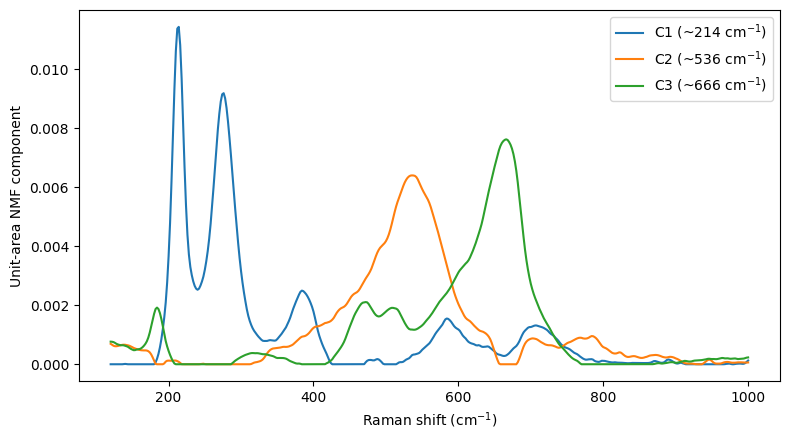

Data-aware RUN HASH: 463d1df82081


In [ ]:
# ============================================================
# 4. Raman preprocessing and CV-safe NMF representation
# ============================================================

def read_raman_csv(path):
    path = Path(path)
    attempts = [
        dict(header=None, sep=","),
        dict(header=None, sep=None, engine="python"),
    ]
    last_err = None
    for kw in attempts:
        try:
            tmp = pd.read_csv(path, **kw)
            if tmp.shape[1] < 2:
                continue
            x = pd.to_numeric(tmp.iloc[:, 0], errors="coerce")
            y = pd.to_numeric(tmp.iloc[:, 1], errors="coerce")
            keep = x.notna() & y.notna()
            x = x[keep].to_numpy(float)
            y = y[keep].to_numpy(float)
            if len(x) >= 20:
                order = np.argsort(x)
                x, y = x[order], y[order]
                ux, idx = np.unique(x, return_index=True)
                return ux, y[idx]
        except Exception as e:
            last_err = e
    raise ValueError(f"Could not parse Raman file {path}: {last_err}")


def als_baseline(y, lam=1e6, p=0.01, niter=12):
    y = np.asarray(y, dtype=float)
    L = len(y)
    D = sparse.diags([1.0, -2.0, 1.0], [0, 1, 2], shape=(L - 2, L), format="csc")
    w = np.ones(L)
    for _ in range(niter):
        W = sparse.spdiags(w, 0, L, L)
        Z = W + lam * (D.T @ D)
        z = spsolve(Z, w * y)
        w = p * (y > z) + (1 - p) * (y < z)
    return np.asarray(z)


def despike(y, kernel=5, z_thresh=8.0):
    y = np.asarray(y, dtype=float).copy()
    if kernel % 2 == 0:
        kernel += 1
    med = medfilt(y, kernel_size=kernel)
    resid = y - med
    mad = np.median(np.abs(resid - np.median(resid)))
    sigma = max(1.4826 * mad, 1e-12)
    spikes = np.abs(resid) > z_thresh * sigma
    y[spikes] = med[spikes]
    return y, int(spikes.sum())


def preprocess_single_raman(x, y, grid):
    y, spike_count = despike(y, RAMAN_DESPIKE_KERNEL, RAMAN_DESPIKE_Z)
    win = min(RAMAN_SAVGOL_WINDOW, len(y) - (1 - len(y) % 2))
    if win % 2 == 0:
        win -= 1
    win = max(win, RAMAN_SAVGOL_POLYORDER + 2 + (RAMAN_SAVGOL_POLYORDER + 2) % 2)
    if win >= len(y):
        win = len(y) - 1 if len(y) % 2 == 0 else len(y)
    if win % 2 == 0:
        win -= 1
    y_smooth = savgol_filter(y, window_length=win, polyorder=min(RAMAN_SAVGOL_POLYORDER, win - 1))
    baseline = als_baseline(y_smooth, RAMAN_ALS_LAMBDA, RAMAN_ALS_P, RAMAN_ALS_NITER)
    corrected = np.clip(y_smooth - baseline, 0.0, None)
    interp = np.interp(grid, x, corrected)
    area = np.trapezoid(interp, grid)
    if not np.isfinite(area) or area <= 1e-12:
        raise ValueError("Raman spectrum has zero/invalid integrated intensity after preprocessing.")
    interp /= area
    return interp, spike_count


def locate_raman_file(sample_name):
    candidates = [
        Path(RAMAN_DIR) / f"{sample_name}.csv",
        Path(RAMAN_DIR) / f"{sample_name}.CSV",
    ]
    for p in candidates:
        if p.exists():
            return p
    return None


RAMAN_GRID = np.arange(RAMAN_MIN_CM, RAMAN_MAX_CM + 0.5 * RAMAN_GRID_STEP_CM, RAMAN_GRID_STEP_CM)
RAMAN_PREPROCESSED = None
RAMAN_SPIKE_COUNTS = None
RAMAN_FILES = {}

if USE_RAW_RAMAN:
    spectra = []
    spikes = []
    missing = []
    for name in train_df[NAME_COL].astype(str):
        path = locate_raman_file(name)
        if path is None:
            missing.append(name)
            spectra.append(None)
            spikes.append(np.nan)
            continue
        x, y = read_raman_csv(path)
        if x.min() > RAMAN_MIN_CM or x.max() < RAMAN_MAX_CM:
            raise ValueError(f"{name}: Raman range {x.min():.2f}-{x.max():.2f} cm^-1 does not cover {RAMAN_MIN_CM}-{RAMAN_MAX_CM}.")
        spec, nspike = preprocess_single_raman(x, y, RAMAN_GRID)
        spectra.append(spec)
        spikes.append(nspike)
        RAMAN_FILES[name] = str(path)

    if missing:
        msg = f"Missing Raman files for: {missing}"
        if RAMAN_REQUIRE_ALL and not (PLACEHOLDER_MODE and RAMAN_ALLOW_CSV_FALLBACK):
            raise FileNotFoundError(msg)
        print("WARNING:", msg)
        print("Falling back to the CSV Raman ratios only for placeholder/testing rows; CV-safe NMF is unavailable for those rows.")

    if not missing:
        RAMAN_PREPROCESSED = np.vstack(spectra).astype(float)
        RAMAN_SPIKE_COUNTS = np.asarray(spikes, dtype=float)

if RAMAN_PREPROCESSED is None:
    if not RAMAN_ALLOW_CSV_FALLBACK:
        raise RuntimeError("Raw Raman spectra are unavailable and RAMAN_ALLOW_CSV_FALLBACK=False.")
    print("Raman mode: CSV ratio fallback. Scientific runs should use all 30 raw spectra.")
else:
    print("Raman mode: raw spectra + fold-safe NMF")
    print("Raman matrix:", RAMAN_PREPROCESSED.shape, "grid:", (RAMAN_GRID[0], RAMAN_GRID[-1], len(RAMAN_GRID)))


def fit_nmf_basis(X_train, n_components=3, seed=0):
    model = NMF(
        n_components=n_components,
        init="nndsvda",
        solver="cd",
        max_iter=RAMAN_NMF_MAX_ITER,
        random_state=seed,
    )
    W = model.fit_transform(np.clip(X_train, 0.0, None))
    H = model.components_.copy()
    areas = np.trapezoid(H, RAMAN_GRID, axis=1)
    areas = np.where(areas <= 1e-12, 1.0, areas)
    H_unit = H / areas[:, None]
    peaks = RAMAN_GRID[np.argmax(H_unit, axis=1)]
    order = np.argsort(peaks)
    return model, order.astype(int), peaks[order], H_unit[order], areas


def nmf_fractions(model, order, areas, X):
    W = model.transform(np.clip(X, 0.0, None))
    W_adj = W * areas[None, :]
    W_adj = W_adj[:, order]
    denom = W_adj.sum(axis=1, keepdims=True)
    denom = np.where(denom <= 1e-12, 1.0, denom)
    return W_adj / denom


def csv_raman_simplex(indices):
    return project_two_to_three_simplex(
        train_df.iloc[indices]["raman_1"].to_numpy(float),
        train_df.iloc[indices]["raman_2"].to_numpy(float),
        strict=not PLACEHOLDER_MODE,
        label="Raman CSV ratios",
    )

# Descriptive full-data NMF only. CV below refits NMF inside each training fold.
shared_raman_dir = SHARED_ROOT / "raman"
shared_raman_dir.mkdir(parents=True, exist_ok=True)
if RAMAN_PREPROCESSED is not None:
    full_nmf, full_order, full_peaks, full_components, full_areas = fit_nmf_basis(
        RAMAN_PREPROCESSED, RAMAN_N_COMPONENTS, RAMAN_NMF_SEED
    )
    full_raman_frac = nmf_fractions(full_nmf, full_order, full_areas, RAMAN_PREPROCESSED)
    joblib.dump(
        {"model": full_nmf, "order": full_order, "areas": full_areas, "grid": RAMAN_GRID},
        shared_raman_dir / "full_descriptive_nmf.joblib",
    )
    pd.DataFrame(RAMAN_PREPROCESSED, index=train_df[NAME_COL], columns=RAMAN_GRID).to_csv(
        shared_raman_dir / "preprocessed_spectra_120_1000.csv"
    )
    comp_df = pd.DataFrame(full_components.T, index=RAMAN_GRID, columns=[f"C{i+1}" for i in range(RAMAN_N_COMPONENTS)])
    comp_df.to_csv(shared_raman_dir / "nmf_components_unit_area.csv")
    coeff_df = pd.DataFrame(full_raman_frac, columns=[f"raman_{i+1}" for i in range(RAMAN_N_COMPONENTS)])
    coeff_df.insert(0, NAME_COL, train_df[NAME_COL].values)
    coeff_df.to_csv(shared_raman_dir / "nmf_coefficients_full_descriptive.csv", index=False)
    save_json({"component_peak_cm-1": full_peaks.tolist()}, shared_raman_dir / "nmf_component_peaks.json")

    fig, ax = plt.subplots(figsize=(8, 4.5))
    for i in range(RAMAN_N_COMPONENTS):
        ax.plot(RAMAN_GRID, full_components[i], label=f"C{i+1} (~{full_peaks[i]:.0f} cm$^{{-1}}$)")
    ax.set_xlabel("Raman shift (cm$^{-1}$)")
    ax.set_ylabel("Unit-area NMF component")
    ax.legend()
    fig.tight_layout()
    fig.savefig(shared_raman_dir / "nmf_components.png", dpi=200)
    plt.show()

# Cache signature must change when experimental CSVs or Raman raw files change.
# This prevents stale placeholder checkpoints from being reused after the real data are inserted.
def sha256_file(path, chunk_size=1024*1024):
    h = hashlib.sha256()
    with open(path, "rb") as f:
        while True:
            chunk = f.read(chunk_size)
            if not chunk:
                break
            h.update(chunk)
    return h.hexdigest()

BASE_CONFIG_HASH = CONFIG_HASH
fingerprints = {
    "train_csv_sha256": sha256_file(TRAIN_CSV_PATH),
    "screen_csv_sha256": sha256_file(SCREEN_CSV_PATH),
}
if RAMAN_PREPROCESSED is not None:
    fingerprints["raman_files_sha256"] = {
        name: sha256_file(path) for name, path in sorted(RAMAN_FILES.items())
    }
else:
    fingerprints["raman_files_sha256"] = "csv_ratio_fallback"
CONFIG_HASH = hashlib.sha256(
    json.dumps({"base_config_hash": BASE_CONFIG_HASH, "data": fingerprints}, sort_keys=True).encode()
).hexdigest()[:12]
save_json(
    {"base_config_hash": BASE_CONFIG_HASH, "run_hash": CONFIG_HASH, "data_fingerprints": fingerprints},
    SHARED_ROOT / "run_signature.json",
)
print("Data-aware RUN HASH:", CONFIG_HASH)


In [ ]:
# ============================================================
# 5. Heterostructure representation and physically constrained targets
# ============================================================

def safe_normalize_rows(x):
    x = np.asarray(x, dtype=float)
    denom = x.sum(axis=1, keepdims=True)
    if np.any(denom <= PRESENT_EPS):
        raise ValueError("Zero-sum composition channel encountered.")
    return x / denom


def entropy_norm(w):
    w = np.clip(np.asarray(w, dtype=float), 0.0, None)
    eps = 1e-12
    h = -np.sum(np.where(w > 0, w * np.log(w + eps), 0.0), axis=1)
    return h / np.log(w.shape[1])


def build_heterostructure_features(df):
    raw = df[COMP_COLS].to_numpy(float)
    core_raw = raw[:, :3]
    shell_raw = raw[:, 3:]
    total_raw = raw.sum(axis=1, keepdims=True)
    core_sum = core_raw.sum(axis=1, keepdims=True)
    shell_sum = shell_raw.sum(axis=1, keepdims=True)

    core_norm = safe_normalize_rows(core_raw)
    shell_norm = safe_normalize_rows(shell_raw)
    core_share = core_sum / total_raw
    shell_share = shell_sum / total_raw

    def region_feats(norm, share, elements):
        out = [norm, share]
        for prop in PROP_NAMES:
            p = np.asarray([ELEMENT_PROPERTIES[e][prop] for e in elements], dtype=float)
            mean = np.sum(norm * p[None, :], axis=1, keepdims=True)
            var = np.sum(norm * (p[None, :] - mean) ** 2, axis=1, keepdims=True)
            std = np.sqrt(np.maximum(var, 0.0))
            out += [mean, std]
        out += [entropy_norm(norm)[:, None]]
        return np.hstack(out)

    core_feat = region_feats(core_norm, core_share, CORE_ELEMENTS)
    shell_feat = region_feats(shell_norm, shell_share, SHELL_ELEMENTS)

    core_names = CORE_COLS + ["core_inventory_share"]
    shell_names = SHELL_COLS + ["shell_inventory_share"]
    for prop in PROP_NAMES:
        core_names += [f"core_{prop}_wmean", f"core_{prop}_wstd"]
        shell_names += [f"shell_{prop}_wmean", f"shell_{prop}_wstd"]
    core_names += ["core_entropy_norm"]
    shell_names += ["shell_entropy_norm"]

    return {
        "core_raw": core_raw,
        "shell_raw": shell_raw,
        "core_norm": core_norm,
        "shell_norm": shell_norm,
        "core_feat": core_feat,
        "shell_feat": shell_feat,
        "core_names": core_names,
        "shell_names": shell_names,
    }


def corrosion_targets(df):
    weights = df[COMP_COLS].to_numpy(float)
    c = df[CORROSION_COLS].to_numpy(float)
    mask = weights > PRESENT_EPS
    if PLACEHOLDER_MODE:
        c = np.nan_to_num(c, nan=0.0)
        c = np.clip(c, 0.0, 1.0)
    else:
        bad = mask & (~np.isfinite(c) | (c < -SIMPLEX_TOL) | (c > 1 + SIMPLEX_TOL))
        if np.any(bad):
            rows, cols = np.where(bad)
            raise ValueError(f"Invalid corrosion values at observed metal positions: {list(zip(rows.tolist(), cols.tolist()))[:20]}")

    def weighted(values, w):
        den = w.sum(axis=1)
        num = np.sum(w * values, axis=1)
        return num / np.where(den <= PRESENT_EPS, 1.0, den)

    total = weighted(c, weights)
    core = weighted(c[:, :3], weights[:, :3])
    shell = weighted(c[:, 3:], weights[:, 3:])
    return {
        "metal": c,
        "mask": mask,
        "weights": weights,
        "total": total,
        "core": core,
        "shell": shell,
    }


TRAIN_REP = build_heterostructure_features(train_df)
SCREEN_REP = build_heterostructure_features(screen_df)
CORR = corrosion_targets(train_df)

O3_ALL = project_two_to_three_simplex(
    train_df["O_lattice"].to_numpy(float),
    train_df["O_vacancy"].to_numpy(float),
    strict=not PLACEHOLDER_MODE,
    label="O 1s ratios",
)

# Full descriptive Raman ratios for processed table only; CV uses fold-specific NMF.
if RAMAN_PREPROCESSED is not None:
    RAMAN3_DESCRIPTIVE = full_raman_frac
else:
    RAMAN3_DESCRIPTIVE = csv_raman_simplex(np.arange(len(train_df)))

processed = train_df.copy()
processed["O_surface"] = O3_ALL[:, 2]
processed["raman_1"] = RAMAN3_DESCRIPTIVE[:, 0]
processed["raman_2"] = RAMAN3_DESCRIPTIVE[:, 1]
processed["raman_3"] = RAMAN3_DESCRIPTIVE[:, 2]
processed["corrosion_core"] = CORR["core"]
processed["corrosion_shell"] = CORR["shell"]
processed["corrosion_total"] = CORR["total"]
processed_dir = SHARED_ROOT / "processed"
processed_dir.mkdir(parents=True, exist_ok=True)
processed.to_csv(processed_dir / "SEAWATER_train_processed.csv", index=False)

print("Core feature dimension:", TRAIN_REP["core_feat"].shape[1], TRAIN_REP["core_names"])
print("Shell feature dimension:", TRAIN_REP["shell_feat"].shape[1], TRAIN_REP["shell_names"])
display(processed[[NAME_COL, "O_lattice", "O_vacancy", "O_surface", "raman_1", "raman_2", "raman_3", "corrosion_core", "corrosion_shell", "corrosion_total"]].head())

Core feature dimension: 13 ['core_Fe', 'core_Co', 'core_Ni', 'core_inventory_share', 'core_valence_wmean', 'core_valence_wstd', 'core_ionization_wmean', 'core_ionization_wstd', 'core_electronegativity_wmean', 'core_electronegativity_wstd', 'core_radius_wmean', 'core_radius_wstd', 'core_entropy_norm']
Shell feature dimension: 14 ['shell_Ti', 'shell_Cr', 'shell_Mo', 'shell_W', 'shell_inventory_share', 'shell_valence_wmean', 'shell_valence_wstd', 'shell_ionization_wmean', 'shell_ionization_wstd', 'shell_electronegativity_wmean', 'shell_electronegativity_wstd', 'shell_radius_wmean', 'shell_radius_wstd', 'shell_entropy_norm']


,name,O_lattice,O_vacancy,O_surface,raman_1,raman_2,raman_3,corrosion_core,corrosion_shell,corrosion_total
0,S01,0.700447,0.203456,0.096096,0.000000,0.000000,1.000000,0.714286,0.737742,0.726014
1,S02,0.682175,0.199245,0.118579,0.000000,0.602877,0.397123,0.499160,0.304722,0.401941
2,S03,0.524852,0.296834,0.178314,0.000000,0.129947,0.870053,0.569748,0.408098,0.488923
3,S04,0.250043,0.392734,0.357222,0.009031,0.769213,0.221756,0.789448,1.000000,0.894724
4,S05,0.564900,0.199091,0.236009,0.038378,0.961622,0.000000,0.684171,0.767179,0.725675


In [ ]:
# ============================================================
# 6. CV split utilities and fold-safe data preparation
# ============================================================

def make_splits(indices, cv_type, seed=CV_SPLIT_SEED):
    indices = np.asarray(indices, dtype=int)
    n = len(indices)
    if cv_type == "5CV":
        splitter = KFold(n_splits=5, shuffle=True, random_state=seed)
        return [(indices[tr], indices[va]) for tr, va in splitter.split(indices)]
    if cv_type == "10CV":
        splitter = KFold(n_splits=10, shuffle=True, random_state=seed)
        return [(indices[tr], indices[va]) for tr, va in splitter.split(indices)]
    if cv_type == "LOOCV":
        splitter = LeaveOneOut()
        return [(indices[tr], indices[va]) for tr, va in splitter.split(indices)]
    raise ValueError(f"Unsupported CV type: {cv_type}")


def fit_feature_scalers(train_idx):
    core_scaler = StandardScaler().fit(TRAIN_REP["core_feat"][train_idx])
    shell_scaler = StandardScaler().fit(TRAIN_REP["shell_feat"][train_idx])
    return core_scaler, shell_scaler


def transform_rep(rep, indices, core_scaler, shell_scaler):
    return {
        "core_x": core_scaler.transform(rep["core_feat"][indices]).astype(np.float32),
        "shell_x": shell_scaler.transform(rep["shell_feat"][indices]).astype(np.float32),
        "core_comp": rep["core_norm"][indices].astype(np.float32),
        "shell_comp": rep["shell_norm"][indices].astype(np.float32),
    }


def fit_fold_raman(train_idx, val_idx=None):
    train_idx = np.asarray(train_idx, dtype=int)
    val_idx = None if val_idx is None else np.asarray(val_idx, dtype=int)
    if RAMAN_PREPROCESSED is None:
        train_r = csv_raman_simplex(train_idx)
        val_r = None if val_idx is None else csv_raman_simplex(val_idx)
        return train_r, val_r, None

    model, order, peaks, H_unit, areas = fit_nmf_basis(
        RAMAN_PREPROCESSED[train_idx], RAMAN_N_COMPONENTS, RAMAN_NMF_SEED
    )
    train_r = nmf_fractions(model, order, areas, RAMAN_PREPROCESSED[train_idx])
    val_r = None if val_idx is None else nmf_fractions(model, order, areas, RAMAN_PREPROCESSED[val_idx])
    state = {
        "model": model,
        "order": order,
        "areas": areas,
        "peaks": peaks,
        "components_unit_area": H_unit,
        "grid": RAMAN_GRID,
    }
    return train_r, val_r, state


def prepare_split(train_idx, val_idx=None):
    train_idx = np.asarray(train_idx, dtype=int)
    val_idx_arr = None if val_idx is None else np.asarray(val_idx, dtype=int)
    core_scaler, shell_scaler = fit_feature_scalers(train_idx)
    tr = transform_rep(TRAIN_REP, train_idx, core_scaler, shell_scaler)
    va = None if val_idx_arr is None else transform_rep(TRAIN_REP, val_idx_arr, core_scaler, shell_scaler)

    tr_r, va_r, nmf_state = fit_fold_raman(train_idx, val_idx_arr)
    tr_spec = np.hstack([O3_ALL[train_idx], tr_r]).astype(np.float32)
    va_spec = None if val_idx_arr is None else np.hstack([O3_ALL[val_idx_arr], va_r]).astype(np.float32)

    tr.update({"indices": train_idx, "spec_target6": tr_spec})
    if va is not None:
        va.update({"indices": val_idx_arr, "spec_target6": va_spec})
    return {
        "train": tr,
        "val": va,
        "core_scaler": core_scaler,
        "shell_scaler": shell_scaler,
        "nmf_state": nmf_state,
    }


outer_splits = make_splits(np.arange(len(train_df)), CV_TYPE, CV_SPLIT_SEED)
cv_split_dir = SHARED_ROOT / "cv_splits" / CV_TYPE
cv_split_dir.mkdir(parents=True, exist_ok=True)
fold_rows = []
for k, (tr, te) in enumerate(outer_splits):
    for idx in te:
        fold_rows.append({NAME_COL: train_df.iloc[idx][NAME_COL], "row_index": int(idx), "outer_fold": int(k)})
pd.DataFrame(fold_rows).sort_values("row_index").to_csv(cv_split_dir / "fold_assignments.csv", index=False)
save_json(
    [{"fold": k, "train_idx": tr.tolist(), "test_idx": te.tolist()} for k, (tr, te) in enumerate(outer_splits)],
    cv_split_dir / "outer_splits.json",
)
print(f"Prepared {len(outer_splits)} outer folds for {CV_TYPE}.")

Prepared 5 outer folds for 5CV.


In [ ]:
# ============================================================
# 7. PyTorch models: shared spectroscopy generator + target-specific HNL predictors
# ============================================================

class TinyMLP(nn.Module):
    def __init__(self, in_dim, out_dim, hidden_dim=4):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(in_dim, hidden_dim),
            nn.Tanh(),
            nn.Linear(hidden_dim, out_dim),
        )
    def forward(self, x):
        return self.net(x)


class LowRankBilinear(nn.Module):
    def __init__(self, core_dim=3, shell_dim=4, rank=2, out_dim=1):
        super().__init__()
        self.U = nn.Parameter(torch.empty(core_dim, rank))
        self.V = nn.Parameter(torch.empty(shell_dim, rank))
        self.out = nn.Linear(rank, out_dim, bias=False)
        nn.init.xavier_uniform_(self.U)
        nn.init.xavier_uniform_(self.V)
        nn.init.xavier_uniform_(self.out.weight)

    def forward(self, core_comp, shell_comp):
        latent = (core_comp @ self.U) * (shell_comp @ self.V)
        return self.out(latent)

    def effective_matrix(self):
        # Returns [out_dim, core_dim, shell_dim]
        W = self.out.weight  # [out, rank]
        mats = []
        for o in range(W.shape[0]):
            A = torch.zeros(self.U.shape[0], self.V.shape[0], device=self.U.device)
            for r in range(self.U.shape[1]):
                A = A + W[o, r] * torch.outer(self.U[:, r], self.V[:, r])
            mats.append(A)
        return torch.stack(mats, dim=0)


class SpectroscopyGenerator(nn.Module):
    """Composition hierarchy -> O 1s simplex (3) + Raman NMF simplex (3). Always trained synchronously."""
    def __init__(self, core_dim, shell_dim, hidden_dim=4, rank=2):
        super().__init__()
        self.core_module = TinyMLP(core_dim, 6, hidden_dim)
        self.shell_module = TinyMLP(shell_dim, 6, hidden_dim)
        self.interface_module = LowRankBilinear(3, 4, rank, 6)
        self.bias = nn.Parameter(torch.zeros(6))

    def forward(self, core_x, shell_x, core_comp, shell_comp, return_components=False):
        c = self.core_module(core_x)
        s = self.shell_module(shell_x)
        i = self.interface_module(core_comp, shell_comp)
        logits = c + s + i + self.bias
        o3 = torch.softmax(logits[:, :3], dim=1)
        r3 = torch.softmax(logits[:, 3:], dim=1)
        if return_components:
            return o3, r3, {"core": c, "shell": s, "interface": i}
        return o3, r3


class ScalarHNLRegressor(nn.Module):
    """Additively decomposable scalar target model."""
    def __init__(self, core_dim, shell_dim, hidden_dim=4, rank=2):
        super().__init__()
        self.core_module = TinyMLP(core_dim, 1, hidden_dim)
        self.shell_module = TinyMLP(shell_dim, 1, hidden_dim)
        self.interface_module = LowRankBilinear(3, 4, rank, 1)
        self.spec_module = nn.Linear(4, 1, bias=False)
        self.bias = nn.Parameter(torch.zeros(1))

    def forward(self, core_x, shell_x, core_comp, shell_comp, spec4, return_components=False):
        c = self.core_module(core_x)
        s = self.shell_module(shell_x)
        i = self.interface_module(core_comp, shell_comp)
        m = self.spec_module(spec4)
        y = c + s + i + m + self.bias
        if return_components:
            return y[:, 0], {"core": c[:, 0], "shell": s[:, 0], "interface": i[:, 0], "spectroscopy": m[:, 0]}
        return y[:, 0]


class CorrosionHNLRegressor(nn.Module):
    """Seven metal-specific corrosion logits; physically weighted core/shell/total corrosion is derived downstream."""
    def __init__(self, core_dim, shell_dim, hidden_dim=4, rank=2):
        super().__init__()
        self.core_module = TinyMLP(core_dim, 7, hidden_dim)
        self.shell_module = TinyMLP(shell_dim, 7, hidden_dim)
        self.interface_module = LowRankBilinear(3, 4, rank, 7)
        self.spec_module = nn.Linear(4, 7, bias=False)
        self.bias = nn.Parameter(torch.zeros(7))

    def forward(self, core_x, shell_x, core_comp, shell_comp, spec4, return_components=False):
        c = self.core_module(core_x)
        s = self.shell_module(shell_x)
        i = self.interface_module(core_comp, shell_comp)
        m = self.spec_module(spec4)
        logits = c + s + i + m + self.bias
        corrosion = torch.sigmoid(logits)
        if return_components:
            return corrosion, logits, {"core": c, "shell": s, "interface": i, "spectroscopy": m}
        return corrosion


CORE_DIM = TRAIN_REP["core_feat"].shape[1]
SHELL_DIM = TRAIN_REP["shell_feat"].shape[1]
print("Model input dims:", CORE_DIM, SHELL_DIM)

Model input dims: 13 14


In [ ]:
# ============================================================
# 8. Losses, clocked optimization, training, prediction, checkpoint helpers
# ============================================================

def cpu_state_dict(model):
    return {k: v.detach().cpu().clone() for k, v in model.state_dict().items()}


def tensor(x, dtype=torch.float32):
    return torch.as_tensor(x, dtype=dtype, device=DEVICE)


def spec4_from_generator(o3, r3):
    return torch.cat([o3[:, :2], r3[:, :2]], dim=1)


def spec_loss_fn(o3_pred, r3_pred, spec_target6):
    o3_true = spec_target6[:, :3]
    r3_true = spec_target6[:, 3:]
    return 0.5 * F.mse_loss(o3_pred, o3_true) + 0.5 * F.mse_loss(r3_pred, r3_true)


def weighted_corrosion_torch(corrosion7, weights7):
    den = weights7.sum(dim=1).clamp_min(1e-12)
    return (corrosion7 * weights7).sum(dim=1) / den


def corrosion_loss_fn(pred7, true7, mask7, weights7, true_total, true_core, true_shell):
    mask = mask7.float()
    metal_sq = (pred7 - true7) ** 2
    metal_loss = (metal_sq * mask).sum() / mask.sum().clamp_min(1.0)

    pred_total = weighted_corrosion_torch(pred7, weights7)
    pred_core = weighted_corrosion_torch(pred7[:, :3], weights7[:, :3])
    pred_shell = weighted_corrosion_torch(pred7[:, 3:], weights7[:, 3:])
    total_loss = F.mse_loss(pred_total, true_total)
    region_loss = 0.5 * (F.mse_loss(pred_core, true_core) + F.mse_loss(pred_shell, true_shell))
    w = CORROSION_LOSS_WEIGHTS
    loss = w["total"] * total_loss + w["region"] * region_loss + w["metal"] * metal_loss
    return loss, {"total": total_loss, "region": region_loss, "metal": metal_loss}


def set_module_clock_trainability(model, schedule, epoch):
    schedule = tuple(int(x) for x in schedule)
    due = {
        "core": epoch % schedule[0] == 0,
        "interface": epoch % schedule[1] == 0,
        "shell": epoch % schedule[2] == 0,
    }
    for name, module in [
        ("core", model.core_module),
        ("interface", model.interface_module),
        ("shell", model.shell_module),
    ]:
        for p in module.parameters():
            p.requires_grad = due[name]
    # spectroscopy head and bias are synchronous by design.
    for p in model.spec_module.parameters():
        p.requires_grad = True
    model.bias.requires_grad = True
    return due


def reset_all_trainable(model):
    for p in model.parameters():
        p.requires_grad = True


def generator_forward_numpy(model, data):
    model.eval()
    with torch.no_grad():
        o3, r3 = model(
            tensor(data["core_x"]), tensor(data["shell_x"]),
            tensor(data["core_comp"]), tensor(data["shell_comp"]),
        )
        spec4 = spec4_from_generator(o3, r3)
    return spec4.cpu().numpy(), o3.cpu().numpy(), r3.cpu().numpy()


def train_spec_generator(train_data, val_data=None, seed=0, fixed_epochs=None):
    set_global_seed(seed)
    model = SpectroscopyGenerator(CORE_DIM, SHELL_DIM, HIDDEN_DIM, INTERFACE_RANK).to(DEVICE)
    opt = torch.optim.AdamW(model.parameters(), lr=SPEC_LEARNING_RATE, weight_decay=SPEC_WEIGHT_DECAY)

    tr_spec = tensor(train_data["spec_target6"])
    best_state = None
    best_loss = np.inf
    best_epoch = 0
    wait = 0
    max_epochs = int(fixed_epochs if fixed_epochs is not None else SPEC_MAX_INNER_EPOCHS)

    for epoch in range(max_epochs):
        model.train()
        opt.zero_grad(set_to_none=True)
        o3, r3 = model(
            tensor(train_data["core_x"]), tensor(train_data["shell_x"]),
            tensor(train_data["core_comp"]), tensor(train_data["shell_comp"]),
        )
        loss = spec_loss_fn(o3, r3, tr_spec)
        loss.backward()
        torch.nn.utils.clip_grad_norm_(model.parameters(), GRAD_CLIP_NORM)
        opt.step()

        if val_data is not None:
            model.eval()
            with torch.no_grad():
                vo3, vr3 = model(
                    tensor(val_data["core_x"]), tensor(val_data["shell_x"]),
                    tensor(val_data["core_comp"]), tensor(val_data["shell_comp"]),
                )
                vloss = float(spec_loss_fn(vo3, vr3, tensor(val_data["spec_target6"])).cpu())
            if vloss < best_loss - 1e-10:
                best_loss = vloss
                best_epoch = epoch + 1
                best_state = cpu_state_dict(model)
                wait = 0
            else:
                wait += 1
            if epoch + 1 >= SPEC_MIN_INNER_EPOCHS and wait >= SPEC_INNER_PATIENCE:
                break

    if val_data is None:
        best_state = cpu_state_dict(model)
        best_epoch = max_epochs
        best_loss = np.nan
    else:
        model.load_state_dict(best_state)
    return model, {"best_epoch": int(best_epoch), "val_loss": float(best_loss), "state_dict": best_state}


def build_target_arrays(indices):
    indices = np.asarray(indices, dtype=int)
    return {
        "overpotential": train_df.iloc[indices]["overpotential"].to_numpy(float).astype(np.float32),
        "stability": train_df.iloc[indices]["stability"].to_numpy(float).astype(np.float32),
        "corrosion_metal": CORR["metal"][indices].astype(np.float32),
        "corrosion_mask": CORR["mask"][indices],
        "corrosion_weights": CORR["weights"][indices].astype(np.float32),
        "corrosion_total": CORR["total"][indices].astype(np.float32),
        "corrosion_core": CORR["core"][indices].astype(np.float32),
        "corrosion_shell": CORR["shell"][indices].astype(np.float32),
    }


def scalar_standardizer(y):
    y = np.asarray(y, dtype=float)
    mu = float(np.mean(y))
    sd = float(np.std(y, ddof=0))
    if sd < 1e-12:
        sd = 1.0
    return mu, sd


def train_scalar_target(target_name, train_data, train_spec4, train_y, schedule,
                        val_data=None, val_spec4=None, val_y=None, seed=0, fixed_epochs=None):
    set_global_seed(seed)
    model = ScalarHNLRegressor(CORE_DIM, SHELL_DIM, HIDDEN_DIM, INTERFACE_RANK).to(DEVICE)
    opt = torch.optim.AdamW(model.parameters(), lr=LEARNING_RATE, weight_decay=WEIGHT_DECAY)
    mu, sd = scalar_standardizer(train_y)
    ytr = tensor((np.asarray(train_y) - mu) / sd)

    best_state = None
    best_loss = np.inf
    best_epoch = 0
    wait = 0
    max_epochs = int(fixed_epochs if fixed_epochs is not None else MAX_INNER_EPOCHS)

    for epoch in range(max_epochs):
        model.train()
        set_module_clock_trainability(model, schedule, epoch)
        opt.zero_grad(set_to_none=True)
        pred = model(
            tensor(train_data["core_x"]), tensor(train_data["shell_x"]),
            tensor(train_data["core_comp"]), tensor(train_data["shell_comp"]), tensor(train_spec4)
        )
        loss = F.mse_loss(pred, ytr)
        loss.backward()
        torch.nn.utils.clip_grad_norm_(model.parameters(), GRAD_CLIP_NORM)
        opt.step()

        if val_data is not None:
            model.eval()
            with torch.no_grad():
                vp = model(
                    tensor(val_data["core_x"]), tensor(val_data["shell_x"]),
                    tensor(val_data["core_comp"]), tensor(val_data["shell_comp"]), tensor(val_spec4)
                )
                vy = tensor((np.asarray(val_y) - mu) / sd)
                vloss = float(F.mse_loss(vp, vy).cpu())
            if vloss < best_loss - 1e-10:
                best_loss = vloss
                best_epoch = epoch + 1
                best_state = cpu_state_dict(model)
                wait = 0
            else:
                wait += 1
            if epoch + 1 >= MIN_INNER_EPOCHS and wait >= INNER_PATIENCE:
                break

    reset_all_trainable(model)
    if val_data is None:
        best_state = cpu_state_dict(model)
        best_epoch = max_epochs
        best_loss = np.nan
    else:
        model.load_state_dict(best_state)
    return model, {"mu": mu, "sd": sd, "best_epoch": int(best_epoch), "val_loss": float(best_loss), "state_dict": best_state}


def train_corrosion_target(train_data, train_spec4, train_targets, schedule,
                           val_data=None, val_spec4=None, val_targets=None, seed=0, fixed_epochs=None):
    set_global_seed(seed)
    model = CorrosionHNLRegressor(CORE_DIM, SHELL_DIM, HIDDEN_DIM, INTERFACE_RANK).to(DEVICE)
    opt = torch.optim.AdamW(model.parameters(), lr=LEARNING_RATE, weight_decay=WEIGHT_DECAY)
    best_state = None
    best_loss = np.inf
    best_epoch = 0
    wait = 0
    max_epochs = int(fixed_epochs if fixed_epochs is not None else MAX_INNER_EPOCHS)

    tr7 = tensor(train_targets["corrosion_metal"])
    trmask = tensor(train_targets["corrosion_mask"], dtype=torch.bool)
    trw = tensor(train_targets["corrosion_weights"])
    trtot = tensor(train_targets["corrosion_total"])
    trcore = tensor(train_targets["corrosion_core"])
    trshell = tensor(train_targets["corrosion_shell"])

    for epoch in range(max_epochs):
        model.train()
        set_module_clock_trainability(model, schedule, epoch)
        opt.zero_grad(set_to_none=True)
        pred7 = model(
            tensor(train_data["core_x"]), tensor(train_data["shell_x"]),
            tensor(train_data["core_comp"]), tensor(train_data["shell_comp"]), tensor(train_spec4)
        )
        loss, _ = corrosion_loss_fn(pred7, tr7, trmask, trw, trtot, trcore, trshell)
        loss.backward()
        torch.nn.utils.clip_grad_norm_(model.parameters(), GRAD_CLIP_NORM)
        opt.step()

        if val_data is not None:
            model.eval()
            with torch.no_grad():
                vp7 = model(
                    tensor(val_data["core_x"]), tensor(val_data["shell_x"]),
                    tensor(val_data["core_comp"]), tensor(val_data["shell_comp"]), tensor(val_spec4)
                )
                vl, _ = corrosion_loss_fn(
                    vp7,
                    tensor(val_targets["corrosion_metal"]),
                    tensor(val_targets["corrosion_mask"], dtype=torch.bool),
                    tensor(val_targets["corrosion_weights"]),
                    tensor(val_targets["corrosion_total"]),
                    tensor(val_targets["corrosion_core"]),
                    tensor(val_targets["corrosion_shell"]),
                )
                vloss = float(vl.cpu())
            if vloss < best_loss - 1e-10:
                best_loss = vloss
                best_epoch = epoch + 1
                best_state = cpu_state_dict(model)
                wait = 0
            else:
                wait += 1
            if epoch + 1 >= MIN_INNER_EPOCHS and wait >= INNER_PATIENCE:
                break

    reset_all_trainable(model)
    if val_data is None:
        best_state = cpu_state_dict(model)
        best_epoch = max_epochs
        best_loss = np.nan
    else:
        model.load_state_dict(best_state)
    return model, {"best_epoch": int(best_epoch), "val_loss": float(best_loss), "state_dict": best_state}


def predict_scalar(model, data, spec4, mu, sd, return_components=False):
    model.eval()
    with torch.no_grad():
        if return_components:
            yp, comps = model(
                tensor(data["core_x"]), tensor(data["shell_x"]), tensor(data["core_comp"]),
                tensor(data["shell_comp"]), tensor(spec4), return_components=True
            )
            pred = yp.cpu().numpy() * sd + mu
            comps_np = {k: v.cpu().numpy() * sd for k, v in comps.items()}
            return pred, comps_np
        yp = model(
            tensor(data["core_x"]), tensor(data["shell_x"]), tensor(data["core_comp"]),
            tensor(data["shell_comp"]), tensor(spec4)
        )
        return yp.cpu().numpy() * sd + mu


def predict_corrosion(model, data, spec4, weights7, return_components=False):
    model.eval()
    w = np.asarray(weights7, dtype=float)
    with torch.no_grad():
        if return_components:
            p7, logits, comps = model(
                tensor(data["core_x"]), tensor(data["shell_x"]), tensor(data["core_comp"]),
                tensor(data["shell_comp"]), tensor(spec4), return_components=True
            )
            p7n = p7.cpu().numpy()
            comp_np = {k: v.cpu().numpy() for k, v in comps.items()}
        else:
            p7n = model(
                tensor(data["core_x"]), tensor(data["shell_x"]), tensor(data["core_comp"]),
                tensor(data["shell_comp"]), tensor(spec4)
            ).cpu().numpy()
            comp_np = None
    den = np.maximum(w.sum(axis=1), 1e-12)
    total = np.sum(p7n * w, axis=1) / den
    core = np.sum(p7n[:, :3] * w[:, :3], axis=1) / np.maximum(w[:, :3].sum(axis=1), 1e-12)
    shell = np.sum(p7n[:, 3:] * w[:, 3:], axis=1) / np.maximum(w[:, 3:].sum(axis=1), 1e-12)
    out = {"metal": p7n, "total": total, "core": core, "shell": shell}
    if return_components:
        out["components_logits"] = comp_np
    return out

In [ ]:
# ============================================================
# 9. Shared spectroscopy generator caches
#     - Inner generators are fit only on inner-training samples.
#     - Outer/full generators are shared by nested and hierarchical variants.
# ============================================================

def cache_signature_ok(meta_path):
    meta_path = Path(meta_path)
    if not meta_path.exists():
        return False
    try:
        meta = json.load(open(meta_path, "r", encoding="utf-8"))
        return meta.get("config_hash") == CONFIG_HASH
    except Exception:
        return False


def save_preparation_objects(prep, folder):
    folder = Path(folder)
    folder.mkdir(parents=True, exist_ok=True)
    joblib.dump(prep["core_scaler"], folder / "core_scaler.joblib")
    joblib.dump(prep["shell_scaler"], folder / "shell_scaler.joblib")
    if prep["nmf_state"] is not None:
        joblib.dump(prep["nmf_state"], folder / "raman_nmf.joblib")


def ensure_inner_generator_cache(scope_name, parent_indices, inner_fold, inner_train_idx, inner_val_idx):
    folder = SHARED_ROOT / "generator_cache" / scope_name / f"inner_{inner_fold:02d}"
    meta_path = folder / "meta.json"
    npz_path = folder / "generated_spec.npz"
    ckpt_path = folder / "spec_generator.pt"
    if RESUME and cache_signature_ok(meta_path) and npz_path.exists() and ckpt_path.exists():
        d = np.load(npz_path, allow_pickle=False)
        meta = json.load(open(meta_path, "r", encoding="utf-8"))
        return {
            "folder": folder,
            "train_idx": d["train_idx"], "val_idx": d["val_idx"],
            "train_core_x": d["train_core_x"], "train_shell_x": d["train_shell_x"],
            "train_core_comp": d["train_core_comp"], "train_shell_comp": d["train_shell_comp"],
            "val_core_x": d["val_core_x"], "val_shell_x": d["val_shell_x"],
            "val_core_comp": d["val_core_comp"], "val_shell_comp": d["val_shell_comp"],
            "train_spec4": d["train_spec4"], "val_spec4": d["val_spec4"],
            "best_epoch": int(meta["best_epoch"]), "val_loss": float(meta["val_loss"]),
        }

    folder.mkdir(parents=True, exist_ok=True)
    prep = prepare_split(inner_train_idx, inner_val_idx)
    model, info = train_spec_generator(prep["train"], prep["val"], seed=CLOCK_SEARCH_SEED)
    tr_spec4, _, _ = generator_forward_numpy(model, prep["train"])
    va_spec4, _, _ = generator_forward_numpy(model, prep["val"])
    torch.save({
        "config_hash": CONFIG_HASH,
        "state_dict": info["state_dict"],
        "best_epoch": info["best_epoch"],
        "val_loss": info["val_loss"],
    }, ckpt_path)
    save_preparation_objects(prep, folder)
    np.savez_compressed(
        npz_path,
        train_idx=np.asarray(inner_train_idx, dtype=int), val_idx=np.asarray(inner_val_idx, dtype=int),
        train_core_x=prep["train"]["core_x"], train_shell_x=prep["train"]["shell_x"],
        train_core_comp=prep["train"]["core_comp"], train_shell_comp=prep["train"]["shell_comp"],
        val_core_x=prep["val"]["core_x"], val_shell_x=prep["val"]["shell_x"],
        val_core_comp=prep["val"]["core_comp"], val_shell_comp=prep["val"]["shell_comp"],
        train_spec4=tr_spec4, val_spec4=va_spec4,
    )
    save_json({
        "config_hash": CONFIG_HASH,
        "best_epoch": info["best_epoch"],
        "val_loss": info["val_loss"],
        "parent_indices": np.asarray(parent_indices, dtype=int).tolist(),
    }, meta_path)
    return ensure_inner_generator_cache(scope_name, parent_indices, inner_fold, inner_train_idx, inner_val_idx)


def inner_caches_for_parent(scope_name, parent_indices):
    parent_indices = np.asarray(parent_indices, dtype=int)
    inner_splits = make_splits(parent_indices, INNER_CV_TYPE, CV_SPLIT_SEED + 991)
    caches = []
    for j, (itr, iva) in enumerate(inner_splits):
        caches.append(ensure_inner_generator_cache(scope_name, parent_indices, j, itr, iva))
    return caches


def median_refit_epoch(values, cap):
    vals = [int(v) for v in values if int(v) > 0]
    if not vals:
        return min(300, cap)
    return int(np.clip(np.median(vals), 1, cap))


# Pre-build inner generator caches for every outer fold. These are shared by both variants.
OUTER_INNER_CACHES = {}
OUTER_GEN_REFIT_EPOCHS = {}
for outer_fold, (outer_train_idx, outer_test_idx) in enumerate(outer_splits):
    scope = f"{CV_TYPE}/outer_{outer_fold:02d}"
    caches = inner_caches_for_parent(scope, outer_train_idx)
    OUTER_INNER_CACHES[outer_fold] = caches
    OUTER_GEN_REFIT_EPOCHS[outer_fold] = median_refit_epoch([c["best_epoch"] for c in caches], SPEC_MAX_REFIT_EPOCHS)
    print(f"outer {outer_fold:02d}: spectroscopy refit epochs = {OUTER_GEN_REFIT_EPOCHS[outer_fold]}")

outer 00: spectroscopy refit epochs = 122
outer 01: spectroscopy refit epochs = 80
outer 02: spectroscopy refit epochs = 93
outer 03: spectroscopy refit epochs = 97
outer 04: spectroscopy refit epochs = 114


In [ ]:
# ============================================================
# 10. Target clock search: identical architecture, only update schedule differs
# ============================================================

def variant_name(nested):
    return "nested" if nested else "hierarchical"


def variants_to_run():
    if RUN_MODE == "compare":
        return [False, True]
    if RUN_MODE == "single":
        return [bool(NESTED_LEARNING)]
    raise ValueError("RUN_MODE must be 'single' or 'compare'.")


def schedule_candidates(nested):
    if not nested:
        return [(1, 1, 1)]
    return list(itertools.product(NESTED_CLOCKS, repeat=3))


def cache_to_data(cache, which):
    prefix = "train" if which == "train" else "val"
    return {
        "core_x": cache[f"{prefix}_core_x"],
        "shell_x": cache[f"{prefix}_shell_x"],
        "core_comp": cache[f"{prefix}_core_comp"],
        "shell_comp": cache[f"{prefix}_shell_comp"],
    }


def target_bundle_path(nested, scope_name, target_name, inner_fold):
    return TRAIN_ROOT / variant_name(nested) / "clock_search" / scope_name / target_name / f"inner_{inner_fold:02d}_bundle.pt"


def search_target_schedule(nested, scope_name, target_name, inner_caches):
    candidates = schedule_candidates(nested)
    fold_metrics = []

    for inner_fold, cache in enumerate(inner_caches):
        bundle_path = target_bundle_path(nested, scope_name, target_name, inner_fold)
        bundle_path.parent.mkdir(parents=True, exist_ok=True)
        existing = None
        if RESUME and bundle_path.exists():
            try:
                obj = torch.load(bundle_path, map_location="cpu", weights_only=False)
                if obj.get("config_hash") == CONFIG_HASH and obj.get("candidates") == [list(x) for x in candidates]:
                    existing = obj
            except Exception:
                existing = None

        # Resume at the individual schedule level. The bundle is updated after every completed candidate.
        tr_idx = np.asarray(cache["train_idx"], dtype=int)
        va_idx = np.asarray(cache["val_idx"], dtype=int)
        tr_data = cache_to_data(cache, "train")
        va_data = cache_to_data(cache, "val")
        tr_spec4 = cache["train_spec4"]
        va_spec4 = cache["val_spec4"]
        tr_targets = build_target_arrays(tr_idx)
        va_targets = build_target_arrays(va_idx)

        if existing is None:
            existing = {
                "config_hash": CONFIG_HASH,
                "target": target_name,
                "candidates": [list(x) for x in candidates],
                "entries": {},
            }

        for schedule in candidates:
            key = "-".join(map(str, schedule))
            if key in existing["entries"]:
                continue
            if target_name in ["overpotential", "stability"]:
                model, info = train_scalar_target(
                    target_name, tr_data, tr_spec4, tr_targets[target_name], schedule,
                    val_data=va_data, val_spec4=va_spec4, val_y=va_targets[target_name],
                    seed=CLOCK_SEARCH_SEED,
                )
            elif target_name == "corrosion":
                model, info = train_corrosion_target(
                    tr_data, tr_spec4, tr_targets, schedule,
                    val_data=va_data, val_spec4=va_spec4, val_targets=va_targets,
                    seed=CLOCK_SEARCH_SEED,
                )
            else:
                raise ValueError(target_name)
            existing["entries"][key] = {
                "schedule": list(schedule),
                "best_epoch": info["best_epoch"],
                "val_loss": info["val_loss"],
                "state_dict": info["state_dict"],
                "mu": info.get("mu"),
                "sd": info.get("sd"),
            }
            torch.save(existing, bundle_path)
            if VERBOSE_INNER_SEARCH:
                print(scope_name, target_name, inner_fold, schedule, info["val_loss"], info["best_epoch"])

        for key, entry in existing["entries"].items():
            fold_metrics.append({
                "inner_fold": inner_fold,
                "schedule": tuple(entry["schedule"]),
                "val_loss": float(entry["val_loss"]),
                "best_epoch": int(entry["best_epoch"]),
            })

    score_df = pd.DataFrame(fold_metrics)
    agg = score_df.groupby("schedule").agg(mean_val_loss=("val_loss", "mean"), std_val_loss=("val_loss", "std"), median_epoch=("best_epoch", "median")).reset_index()
    agg = agg.sort_values(["mean_val_loss", "std_val_loss"], na_position="last").reset_index(drop=True)
    best_schedule = tuple(agg.iloc[0]["schedule"])
    selected_rows = score_df[score_df["schedule"] == best_schedule]
    refit_epoch = median_refit_epoch(selected_rows["best_epoch"].tolist(), MAX_REFIT_EPOCHS)

    out_dir = TRAIN_ROOT / variant_name(nested) / "clock_search" / scope_name / target_name
    out_dir.mkdir(parents=True, exist_ok=True)
    score_df.assign(schedule=score_df["schedule"].map(str)).to_csv(out_dir / "all_inner_scores.csv", index=False)
    agg.assign(schedule=agg["schedule"].map(str)).to_csv(out_dir / "schedule_summary.csv", index=False)
    save_json({
        "target": target_name,
        "variant": variant_name(nested),
        "best_schedule": list(best_schedule),
        "clock_order": list(CLOCK_ORDER),
        "refit_epoch": int(refit_epoch),
        "mean_val_loss": float(agg.iloc[0]["mean_val_loss"]),
    }, out_dir / "selected_schedule.json")
    return best_schedule, refit_epoch, agg


# Select target-specific clocks within each outer-training set.
OUTER_SELECTIONS = {False: {}, True: {}}
for nested in variants_to_run():
    vname = variant_name(nested)
    print("\nClock selection for", vname)
    for outer_fold, caches in OUTER_INNER_CACHES.items():
        scope = f"{CV_TYPE}/outer_{outer_fold:02d}"
        sel = {}
        for target in ["overpotential", "stability", "corrosion"]:
            sch, ep, _ = search_target_schedule(nested, scope, target, caches)
            sel[target] = {"schedule": sch, "epochs": ep}
        OUTER_SELECTIONS[nested][outer_fold] = sel
        print(f"outer {outer_fold:02d}:", sel)


Clock selection for hierarchical
outer 00: {'overpotential': {'schedule': (1, 1, 1), 'epochs': 22}, 'stability': {'schedule': (1, 1, 1), 'epochs': 1}, 'corrosion': {'schedule': (1, 1, 1), 'epochs': 110}}
outer 01: {'overpotential': {'schedule': (1, 1, 1), 'epochs': 23}, 'stability': {'schedule': (1, 1, 1), 'epochs': 1}, 'corrosion': {'schedule': (1, 1, 1), 'epochs': 107}}
outer 02: {'overpotential': {'schedule': (1, 1, 1), 'epochs': 42}, 'stability': {'schedule': (1, 1, 1), 'epochs': 10}, 'corrosion': {'schedule': (1, 1, 1), 'epochs': 27}}
outer 03: {'overpotential': {'schedule': (1, 1, 1), 'epochs': 68}, 'stability': {'schedule': (1, 1, 1), 'epochs': 29}, 'corrosion': {'schedule': (1, 1, 1), 'epochs': 207}}
outer 04: {'overpotential': {'schedule': (1, 1, 1), 'epochs': 102}, 'stability': {'schedule': (1, 1, 1), 'epochs': 15}, 'corrosion': {'schedule': (1, 1, 1), 'epochs': 32}}

Clock selection for nested
outer 00: {'overpotential': {'schedule': (1, 16, 4), 'epochs': 44}, 'stability': 

In [ ]:
# ============================================================
# 11. Shared outer generator ensembles and variant outer-CV target ensembles
# ============================================================

def outer_shared_cache_path(outer_fold, seed):
    return SHARED_ROOT / "outer_models" / CV_TYPE / f"outer_{outer_fold:02d}" / f"seed_{seed:02d}"


def ensure_outer_generator(outer_fold, seed, outer_train_idx, outer_test_idx, refit_epochs):
    folder = outer_shared_cache_path(outer_fold, seed)
    folder.mkdir(parents=True, exist_ok=True)
    ckpt_path = folder / "spec_generator.pt"
    npz_path = folder / "generated_spec.npz"
    meta_path = folder / "meta.json"
    if RESUME and cache_signature_ok(meta_path) and ckpt_path.exists() and npz_path.exists():
        d = np.load(npz_path, allow_pickle=False)
        return {k: d[k] for k in d.files}

    prep = prepare_split(outer_train_idx, outer_test_idx)
    model, info = train_spec_generator(prep["train"], None, seed=seed, fixed_epochs=refit_epochs)
    tr_spec4, tr_o3, tr_r3 = generator_forward_numpy(model, prep["train"])
    te_spec4, te_o3, te_r3 = generator_forward_numpy(model, prep["val"])
    torch.save({
        "config_hash": CONFIG_HASH,
        "state_dict": info["state_dict"],
        "seed": seed,
        "refit_epochs": refit_epochs,
    }, ckpt_path)
    save_preparation_objects(prep, folder)
    np.savez_compressed(
        npz_path,
        train_idx=np.asarray(outer_train_idx, dtype=int), test_idx=np.asarray(outer_test_idx, dtype=int),
        train_core_x=prep["train"]["core_x"], train_shell_x=prep["train"]["shell_x"],
        train_core_comp=prep["train"]["core_comp"], train_shell_comp=prep["train"]["shell_comp"],
        test_core_x=prep["val"]["core_x"], test_shell_x=prep["val"]["shell_x"],
        test_core_comp=prep["val"]["core_comp"], test_shell_comp=prep["val"]["shell_comp"],
        train_spec4=tr_spec4, test_spec4=te_spec4,
        train_o3=tr_o3, train_r3=tr_r3, test_o3=te_o3, test_r3=te_r3,
    )
    save_json({"config_hash": CONFIG_HASH, "seed": seed, "refit_epochs": refit_epochs}, meta_path)
    return ensure_outer_generator(outer_fold, seed, outer_train_idx, outer_test_idx, refit_epochs)


def array_data_from_outer_cache(cache, prefix):
    return {
        "core_x": cache[f"{prefix}_core_x"],
        "shell_x": cache[f"{prefix}_shell_x"],
        "core_comp": cache[f"{prefix}_core_comp"],
        "shell_comp": cache[f"{prefix}_shell_comp"],
    }


def outer_target_checkpoint_path(nested, outer_fold, seed, target):
    return TRAIN_ROOT / variant_name(nested) / "cv" / CV_TYPE / f"outer_{outer_fold:02d}" / f"seed_{seed:02d}" / f"{target}.pt"


def fit_or_load_outer_target(nested, outer_fold, seed, target, cache, selection):
    ckpt_path = outer_target_checkpoint_path(nested, outer_fold, seed, target)
    ckpt_path.parent.mkdir(parents=True, exist_ok=True)
    schedule = tuple(selection[target]["schedule"])
    epochs = int(selection[target]["epochs"])

    tr_idx = cache["train_idx"].astype(int)
    te_idx = cache["test_idx"].astype(int)
    tr_data = array_data_from_outer_cache(cache, "train")
    te_data = array_data_from_outer_cache(cache, "test")
    tr_spec4 = cache["train_spec4"]
    te_spec4 = cache["test_spec4"]
    tr_t = build_target_arrays(tr_idx)

    loaded = None
    if RESUME and ckpt_path.exists():
        try:
            obj = torch.load(ckpt_path, map_location="cpu", weights_only=False)
            if obj.get("config_hash") == CONFIG_HASH and tuple(obj.get("schedule", [])) == schedule and int(obj.get("epochs", -1)) == epochs:
                loaded = obj
        except Exception:
            loaded = None

    if target in ["overpotential", "stability"]:
        model = ScalarHNLRegressor(CORE_DIM, SHELL_DIM, HIDDEN_DIM, INTERFACE_RANK).to(DEVICE)
        if loaded is None:
            model, info = train_scalar_target(
                target, tr_data, tr_spec4, tr_t[target], schedule, seed=seed, fixed_epochs=epochs
            )
            obj = {
                "config_hash": CONFIG_HASH, "variant": variant_name(nested), "target": target,
                "seed": seed, "schedule": list(schedule), "epochs": epochs,
                "state_dict": info["state_dict"], "mu": info["mu"], "sd": info["sd"],
            }
            torch.save(obj, ckpt_path)
            loaded = obj
        model.load_state_dict(loaded["state_dict"])
        pred = predict_scalar(model, te_data, te_spec4, float(loaded["mu"]), float(loaded["sd"]))
        return pred, loaded

    if target == "corrosion":
        model = CorrosionHNLRegressor(CORE_DIM, SHELL_DIM, HIDDEN_DIM, INTERFACE_RANK).to(DEVICE)
        if loaded is None:
            model, info = train_corrosion_target(tr_data, tr_spec4, tr_t, schedule, seed=seed, fixed_epochs=epochs)
            obj = {
                "config_hash": CONFIG_HASH, "variant": variant_name(nested), "target": target,
                "seed": seed, "schedule": list(schedule), "epochs": epochs,
                "state_dict": info["state_dict"],
            }
            torch.save(obj, ckpt_path)
            loaded = obj
        model.load_state_dict(loaded["state_dict"])
        weights = train_df.iloc[te_idx][COMP_COLS].to_numpy(float)
        pred = predict_corrosion(model, te_data, te_spec4, weights)
        return pred, loaded
    raise ValueError(target)


OUTER_SHARED_CACHES = {}
for outer_fold, (tr_idx, te_idx) in enumerate(outer_splits):
    OUTER_SHARED_CACHES[outer_fold] = {}
    for seed in SEEDS:
        OUTER_SHARED_CACHES[outer_fold][seed] = ensure_outer_generator(
            outer_fold, seed, tr_idx, te_idx, OUTER_GEN_REFIT_EPOCHS[outer_fold]
        )


def pooled_metrics(y_true, y_pred):
    y_true = np.asarray(y_true, dtype=float)
    y_pred = np.asarray(y_pred, dtype=float)
    ok = np.isfinite(y_true) & np.isfinite(y_pred)
    y_true, y_pred = y_true[ok], y_pred[ok]
    if len(y_true) < 2:
        return {"n": int(len(y_true)), "r2": np.nan, "rmse": np.nan, "mae": np.nan, "spearman": np.nan}
    rho = spearmanr(y_true, y_pred).statistic
    return {
        "n": int(len(y_true)),
        "r2": float(r2_score(y_true, y_pred)),
        "rmse": float(np.sqrt(mean_squared_error(y_true, y_pred))),
        "mae": float(mean_absolute_error(y_true, y_pred)),
        "spearman": float(rho),
    }


def run_variant_cv(nested):
    vname = variant_name(nested)
    variant_root = TRAIN_ROOT / vname
    variant_root.mkdir(parents=True, exist_ok=True)
    all_rows = []
    metal_seed_predictions = {m: [[] for _ in range(len(train_df))] for m in METALS}
    scalar_seed_predictions = {"overpotential": [[] for _ in range(len(train_df))], "stability": [[] for _ in range(len(train_df))], "corrosion_total": [[] for _ in range(len(train_df))]}

    for outer_fold, (tr_idx, te_idx) in enumerate(outer_splits):
        selection = OUTER_SELECTIONS[nested][outer_fold]
        for seed in SEEDS:
            cache = OUTER_SHARED_CACHES[outer_fold][seed]
            op_pred, _ = fit_or_load_outer_target(nested, outer_fold, seed, "overpotential", cache, selection)
            st_pred, _ = fit_or_load_outer_target(nested, outer_fold, seed, "stability", cache, selection)
            co_pred, _ = fit_or_load_outer_target(nested, outer_fold, seed, "corrosion", cache, selection)
            for j, idx in enumerate(te_idx):
                scalar_seed_predictions["overpotential"][idx].append(float(op_pred[j]))
                scalar_seed_predictions["stability"][idx].append(float(st_pred[j]))
                scalar_seed_predictions["corrosion_total"][idx].append(float(co_pred["total"][j]))
                for m_i, m in enumerate(METALS):
                    if CORR["mask"][idx, m_i]:
                        metal_seed_predictions[m][idx].append(float(co_pred["metal"][j, m_i]))

    out = pd.DataFrame({NAME_COL: train_df[NAME_COL].values})
    for target in ["overpotential", "stability", "corrosion_total"]:
        vals = scalar_seed_predictions[target]
        out[f"{target}_pred"] = [np.mean(v) if v else np.nan for v in vals]
        out[f"{target}_std"] = [np.std(v, ddof=0) if v else np.nan for v in vals]
    for m in METALS:
        vals = metal_seed_predictions[m]
        out[f"corrosion_{m}_pred"] = [np.mean(v) if v else np.nan for v in vals]
        out[f"corrosion_{m}_std"] = [np.std(v, ddof=0) if v else np.nan for v in vals]

    out["overpotential_true"] = train_df["overpotential"].values
    out["stability_true"] = train_df["stability"].values
    out["corrosion_total_true"] = CORR["total"]
    for i, m in enumerate(METALS):
        truth = CORR["metal"][:, i].copy()
        truth[~CORR["mask"][:, i]] = np.nan
        out[f"corrosion_{m}_true"] = truth

    cv_dir = variant_root / "cv" / CV_TYPE
    cv_dir.mkdir(parents=True, exist_ok=True)
    out.to_csv(cv_dir / "oof_predictions.csv", index=False)

    metric_rows = []
    for target in ["overpotential", "stability", "corrosion_total"]:
        metric_rows.append({"target": target, **pooled_metrics(out[f"{target}_true"], out[f"{target}_pred"])})
    for m in METALS:
        metric_rows.append({"target": f"corrosion_{m}", **pooled_metrics(out[f"corrosion_{m}_true"], out[f"corrosion_{m}_pred"])})
    metrics = pd.DataFrame(metric_rows)
    metrics.to_csv(cv_dir / "metrics.csv", index=False)
    return out, metrics


CV_RESULTS = {}
for nested in variants_to_run():
    print("\nRunning outer CV:", variant_name(nested))
    CV_RESULTS[nested] = run_variant_cv(nested)
    display(CV_RESULTS[nested][1])


Running outer CV: hierarchical


,target,n,r2,rmse,mae,spearman
0,overpotential,30,-0.568504,66.924695,52.271427,0.068743
1,stability,30,-0.082696,5.024366,3.547742,0.197083
2,corrosion_total,30,0.049824,0.195063,0.159454,0.445606
3,corrosion_Fe,19,-0.712250,0.298837,0.247864,-0.021062
4,corrosion_Co,15,0.056677,0.265729,0.215453,0.146822
5,corrosion_Ni,21,0.180344,0.252211,0.204056,0.402996
6,corrosion_Ti,16,-0.105363,0.279784,0.226755,0.066323
7,corrosion_Cr,17,0.041208,0.302985,0.270280,0.296569
8,corrosion_Mo,11,-0.218749,0.372360,0.342183,0.290909
9,corrosion_W,16,0.217863,0.321438,0.292662,0.479412



Running outer CV: nested


,target,n,r2,rmse,mae,spearman
0,overpotential,30,-0.767040,71.034078,54.586806,-0.119021
1,stability,30,-0.186601,5.259935,3.769042,0.110901
2,corrosion_total,30,0.082615,0.191667,0.146035,0.429588
3,corrosion_Fe,19,-0.789006,0.305462,0.232866,-0.051777
4,corrosion_Co,15,0.070503,0.263774,0.211346,0.273949
5,corrosion_Ni,21,-0.042322,0.284413,0.232443,0.259767
6,corrosion_Ti,16,0.077159,0.255643,0.203375,0.287399
7,corrosion_Cr,17,0.022958,0.305855,0.272637,0.215686
8,corrosion_Mo,11,-0.308998,0.385901,0.354933,0.300000
9,corrosion_W,16,0.239557,0.316949,0.279724,0.608824


In [ ]:
# ============================================================
# 12. Optional conventional baselines on the same outer folds
#     Flat inputs = heterostructure engineered representation + shared generated spectroscopy.
# ============================================================

def make_baseline(name, seed=0):
    if name == "ridge":
        return Ridge(alpha=1.0)
    if name == "pls":
        return PLSRegression(n_components=2, scale=True)
    if name == "gpr":
        kernel = ConstantKernel(1.0, (1e-3, 1e3)) * Matern(length_scale=1.0, nu=1.5) + WhiteKernel(1e-3, (1e-6, 1e0))
        return GaussianProcessRegressor(kernel=kernel, normalize_y=True, random_state=seed, n_restarts_optimizer=2)
    if name == "extratrees":
        return ExtraTreesRegressor(n_estimators=500, min_samples_leaf=2, random_state=seed, n_jobs=-1)
    raise ValueError(name)


def flat_features(cache, prefix):
    c = cache[f"{prefix}_core_x"]
    s = cache[f"{prefix}_shell_x"]
    cc = cache[f"{prefix}_core_comp"]
    sc = cache[f"{prefix}_shell_comp"]
    cross = (cc[:, :, None] * sc[:, None, :]).reshape(len(cc), -1)
    spec = cache[f"{prefix}_spec4"]
    return np.hstack([c, s, cross, spec])


def run_baselines():
    rows = []
    for model_name in BASELINE_MODELS:
        pred_store = {t: np.full(len(train_df), np.nan) for t in ["overpotential", "stability", "corrosion_total"]}
        for outer_fold, (tr_idx, te_idx) in enumerate(outer_splits):
            # Fixed shared generator seed for deterministic/fair baseline preprocessing.
            seed = SEEDS[0]
            cache = OUTER_SHARED_CACHES[outer_fold][seed]
            Xtr = flat_features(cache, "train")
            Xte = flat_features(cache, "test")
            y_map = {
                "overpotential": train_df.iloc[tr_idx]["overpotential"].to_numpy(float),
                "stability": train_df.iloc[tr_idx]["stability"].to_numpy(float),
                "corrosion_total": CORR["total"][tr_idx],
            }
            for target, ytr in y_map.items():
                model_path = BASELINES_ROOT / model_name / CV_TYPE / f"outer_{outer_fold:02d}" / f"{target}.joblib"
                model_path.parent.mkdir(parents=True, exist_ok=True)
                if RESUME and model_path.exists():
                    model = joblib.load(model_path)
                else:
                    model = make_baseline(model_name, seed)
                    model.fit(Xtr, ytr)
                    joblib.dump(model, model_path)
                pred = np.asarray(model.predict(Xte)).reshape(-1)
                pred_store[target][te_idx] = pred
        for target in pred_store:
            ytrue = train_df[target].to_numpy(float) if target in ["overpotential", "stability"] else CORR["total"]
            rows.append({"model": model_name, "target": target, **pooled_metrics(ytrue, pred_store[target])})
    out = pd.DataFrame(rows)
    BASELINES_ROOT.mkdir(parents=True, exist_ok=True)
    out.to_csv(BASELINES_ROOT / f"{CV_TYPE}_metrics.csv", index=False)
    return out


BASELINE_RESULTS = None
if RUN_CONVENTIONAL_BASELINES:
    BASELINE_RESULTS = run_baselines()
    display(BASELINE_RESULTS)

,model,target,n,r2,rmse,mae,spearman
0,ridge,overpotential,30,-20.305617,246.655399,236.753607,-0.201780
1,ridge,stability,30,-1.698997,7.932849,6.478027,-0.249416
2,ridge,corrosion_total,30,0.019419,0.198159,0.150693,0.435373
3,pls,overpotential,30,-36.011330,325.095465,303.232108,-0.138154
4,pls,stability,30,-22.572314,23.443859,19.050948,-0.012693
5,pls,corrosion_total,30,-4.505793,0.469550,0.359404,0.131034
6,gpr,overpotential,30,-20.552514,248.080446,242.190475,-0.110107
7,gpr,stability,30,-0.336984,5.583301,4.622306,0.139512
8,gpr,corrosion_total,30,-0.129993,0.212721,0.180380,0.033992
9,extratrees,overpotential,30,-20.352638,246.927428,239.696990,-0.309455


In [ ]:
# ============================================================
# 13. Nested vs hierarchical paired comparison
# ============================================================

def paired_bootstrap_mae_improvement(y, pred_h, pred_n, n_boot=N_PAIRED_BOOTSTRAP, seed=1234):
    y = np.asarray(y, float); ph = np.asarray(pred_h, float); pn = np.asarray(pred_n, float)
    ok = np.isfinite(y) & np.isfinite(ph) & np.isfinite(pn)
    y, ph, pn = y[ok], ph[ok], pn[ok]
    if len(y) == 0:
        return {}
    d = np.abs(y - ph) - np.abs(y - pn)  # >0 means nested has lower absolute error
    rng = np.random.default_rng(seed)
    boots = np.empty(n_boot)
    for b in range(n_boot):
        idx = rng.integers(0, len(d), len(d))
        boots[b] = np.mean(d[idx])
    try:
        w = wilcoxon(np.abs(y - ph), np.abs(y - pn), zero_method="wilcox", alternative="two-sided")
        p = float(w.pvalue)
    except Exception:
        p = np.nan
    return {
        "n": int(len(d)),
        "mean_abs_error_improvement_h_minus_n": float(np.mean(d)),
        "bootstrap_ci_low": float(np.percentile(boots, 2.5)),
        "bootstrap_ci_high": float(np.percentile(boots, 97.5)),
        "wilcoxon_p": p,
    }


if RUN_MODE == "compare":
    h_oof, h_met = CV_RESULTS[False]
    n_oof, n_met = CV_RESULTS[True]
    comp_rows = []
    for target in ["overpotential", "stability", "corrosion_total"]:
        y = h_oof[f"{target}_true"].to_numpy(float)
        mh = pooled_metrics(y, h_oof[f"{target}_pred"])
        mn = pooled_metrics(y, n_oof[f"{target}_pred"])
        paired = paired_bootstrap_mae_improvement(y, h_oof[f"{target}_pred"], n_oof[f"{target}_pred"])
        comp_rows.append({
            "target": target,
            "hierarchical_r2": mh["r2"], "nested_r2": mn["r2"], "delta_r2_nested_minus_h": mn["r2"] - mh["r2"],
            "hierarchical_rmse": mh["rmse"], "nested_rmse": mn["rmse"], "delta_rmse_nested_minus_h": mn["rmse"] - mh["rmse"],
            "hierarchical_mae": mh["mae"], "nested_mae": mn["mae"], "delta_mae_nested_minus_h": mn["mae"] - mh["mae"],
            **paired,
        })
    comparison_df = pd.DataFrame(comp_rows)
    TRAIN_COMPARISON_ROOT.mkdir(parents=True, exist_ok=True)
    comparison_df.to_csv(TRAIN_COMPARISON_ROOT / f"{CV_TYPE}_nested_vs_hierarchical.csv", index=False)
    display(comparison_df)

,target,hierarchical_r2,nested_r2,delta_r2_nested_minus_h,hierarchical_rmse,nested_rmse,delta_rmse_nested_minus_h,hierarchical_mae,nested_mae,delta_mae_nested_minus_h,n,mean_abs_error_improvement_h_minus_n,bootstrap_ci_low,bootstrap_ci_high,wilcoxon_p
0,overpotential,-0.568504,-0.767040,-0.198536,66.924695,71.034078,4.109383,52.271427,54.586806,2.31538,30,-2.31538,-5.747256,0.977563,0.157948
1,stability,-0.082696,-0.186601,-0.103905,5.024366,5.259935,0.235568,3.547742,3.769042,0.22130,30,-0.22130,-0.556104,0.073157,0.262122
2,corrosion_total,0.049824,0.082615,0.032792,0.195063,0.191667,-0.003395,0.159454,0.146035,-0.01342,30,0.01342,-0.013438,0.039434,0.289366


In [ ]:
# ============================================================
# 14. Full-data model selection and full-data seed ensembles
# ============================================================

FULL_SCOPE = f"full/{INNER_CV_TYPE}"
FULL_INNER_CACHES = inner_caches_for_parent(FULL_SCOPE, np.arange(len(train_df)))
FULL_GEN_EPOCHS = median_refit_epoch([c["best_epoch"] for c in FULL_INNER_CACHES], SPEC_MAX_REFIT_EPOCHS)
print("Full-data spectroscopy refit epochs:", FULL_GEN_EPOCHS)

FULL_SELECTIONS = {}
for nested in variants_to_run():
    sel = {}
    for target in ["overpotential", "stability", "corrosion"]:
        sch, ep, _ = search_target_schedule(nested, FULL_SCOPE, target, FULL_INNER_CACHES)
        sel[target] = {"schedule": sch, "epochs": ep}
    FULL_SELECTIONS[nested] = sel
    save_json(
        {k: {"schedule": list(v["schedule"]), "epochs": int(v["epochs"])} for k, v in sel.items()},
        TRAIN_ROOT / variant_name(nested) / "full" / "selected_clocks.json",
    )
    print(variant_name(nested), sel)


def ensure_full_generator(seed):
    folder = SHARED_ROOT / "full" / f"seed_{seed:02d}"
    folder.mkdir(parents=True, exist_ok=True)
    ckpt_path = folder / "spec_generator.pt"
    cache_path = folder / "train_generated_spec.npz"
    meta_path = folder / "meta.json"
    if RESUME and cache_signature_ok(meta_path) and ckpt_path.exists() and cache_path.exists():
        d = np.load(cache_path, allow_pickle=False)
        return {k: d[k] for k in d.files}

    all_idx = np.arange(len(train_df))
    prep = prepare_split(all_idx, None)
    model, info = train_spec_generator(prep["train"], None, seed=seed, fixed_epochs=FULL_GEN_EPOCHS)
    tr_spec4, tr_o3, tr_r3 = generator_forward_numpy(model, prep["train"])
    torch.save({
        "config_hash": CONFIG_HASH, "state_dict": info["state_dict"], "seed": seed, "epochs": FULL_GEN_EPOCHS,
    }, ckpt_path)
    save_preparation_objects(prep, folder)
    np.savez_compressed(
        cache_path,
        train_idx=all_idx,
        train_core_x=prep["train"]["core_x"], train_shell_x=prep["train"]["shell_x"],
        train_core_comp=prep["train"]["core_comp"], train_shell_comp=prep["train"]["shell_comp"],
        train_spec4=tr_spec4, train_o3=tr_o3, train_r3=tr_r3,
    )
    save_json({"config_hash": CONFIG_HASH, "seed": seed, "epochs": FULL_GEN_EPOCHS}, meta_path)
    return ensure_full_generator(seed)


def fit_or_load_full_target(nested, seed, target, cache, selection):
    out_dir = TRAIN_ROOT / variant_name(nested) / "full" / "checkpoints"
    out_dir.mkdir(parents=True, exist_ok=True)
    ckpt_path = out_dir / f"seed_{seed:02d}_{target}.pt"
    schedule = tuple(selection[target]["schedule"])
    epochs = int(selection[target]["epochs"])
    tr_data = {
        "core_x": cache["train_core_x"], "shell_x": cache["train_shell_x"],
        "core_comp": cache["train_core_comp"], "shell_comp": cache["train_shell_comp"],
    }
    tr_spec4 = cache["train_spec4"]
    tr_t = build_target_arrays(cache["train_idx"].astype(int))

    loaded = None
    if RESUME and ckpt_path.exists():
        try:
            obj = torch.load(ckpt_path, map_location="cpu", weights_only=False)
            if obj.get("config_hash") == CONFIG_HASH and tuple(obj.get("schedule", [])) == schedule and int(obj.get("epochs", -1)) == epochs:
                loaded = obj
        except Exception:
            pass

    if target in ["overpotential", "stability"]:
        model = ScalarHNLRegressor(CORE_DIM, SHELL_DIM, HIDDEN_DIM, INTERFACE_RANK).to(DEVICE)
        if loaded is None:
            model, info = train_scalar_target(target, tr_data, tr_spec4, tr_t[target], schedule, seed=seed, fixed_epochs=epochs)
            loaded = {"config_hash": CONFIG_HASH, "state_dict": info["state_dict"], "mu": info["mu"], "sd": info["sd"],
                      "schedule": list(schedule), "epochs": epochs, "seed": seed, "target": target}
            torch.save(loaded, ckpt_path)
        model.load_state_dict(loaded["state_dict"])
        return model, loaded
    if target == "corrosion":
        model = CorrosionHNLRegressor(CORE_DIM, SHELL_DIM, HIDDEN_DIM, INTERFACE_RANK).to(DEVICE)
        if loaded is None:
            model, info = train_corrosion_target(tr_data, tr_spec4, tr_t, schedule, seed=seed, fixed_epochs=epochs)
            loaded = {"config_hash": CONFIG_HASH, "state_dict": info["state_dict"], "schedule": list(schedule), "epochs": epochs, "seed": seed, "target": target}
            torch.save(loaded, ckpt_path)
        model.load_state_dict(loaded["state_dict"])
        return model, loaded
    raise ValueError(target)


FULL_GENERATOR_CACHES = {seed: ensure_full_generator(seed) for seed in SEEDS}
FULL_TARGET_MODELS = {}
for nested in variants_to_run():
    FULL_TARGET_MODELS[nested] = {}
    for seed in SEEDS:
        cache = FULL_GENERATOR_CACHES[seed]
        FULL_TARGET_MODELS[nested][seed] = {}
        for target in ["overpotential", "stability", "corrosion"]:
            FULL_TARGET_MODELS[nested][seed][target] = fit_or_load_full_target(
                nested, seed, target, cache, FULL_SELECTIONS[nested]
            )
print("Full-data ensembles ready.")

Full-data spectroscopy refit epochs: 95
hierarchical {'overpotential': {'schedule': (1, 1, 1), 'epochs': 42}, 'stability': {'schedule': (1, 1, 1), 'epochs': 11}, 'corrosion': {'schedule': (1, 1, 1), 'epochs': 74}}
nested {'overpotential': {'schedule': (1, 4, 1), 'epochs': 45}, 'stability': {'schedule': (1, 16, 16), 'epochs': 64}, 'corrosion': {'schedule': (4, 1, 1), 'epochs': 89}}
Full-data ensembles ready.


In [ ]:
# ============================================================
# 15. Exhaustive 0.1-grid screening of SEAWATER_screen.csv
# ============================================================

def load_full_generator_for_screen(seed):
    folder = SHARED_ROOT / "full" / f"seed_{seed:02d}"
    ckpt = torch.load(folder / "spec_generator.pt", map_location="cpu", weights_only=False)
    core_scaler = joblib.load(folder / "core_scaler.joblib")
    shell_scaler = joblib.load(folder / "shell_scaler.joblib")
    model = SpectroscopyGenerator(CORE_DIM, SHELL_DIM, HIDDEN_DIM, INTERFACE_RANK).to(DEVICE)
    model.load_state_dict(ckpt["state_dict"])
    screen_data = transform_rep(SCREEN_REP, np.arange(len(screen_df)), core_scaler, shell_scaler)
    spec4, o3, r3 = generator_forward_numpy(model, screen_data)
    return screen_data, spec4, o3, r3


def pareto_mask(values, directions):
    X = np.asarray(values, dtype=float).copy()
    for j, d in enumerate(directions):
        if d == "max":
            X[:, j] *= -1.0
        elif d != "min":
            raise ValueError(d)
    # Standard iterative non-dominated filter; memory-safe for ~18.9k x 3.
    idx = np.arange(X.shape[0])
    pts = X.copy()
    k = 0
    while k < len(pts):
        p = pts[k]
        keep = np.any(pts < p, axis=1) | np.all(np.isclose(pts, p, atol=1e-12, rtol=0), axis=1)
        keep[k] = True
        idx = idx[keep]
        pts = pts[keep]
        k = int(np.sum(keep[:k])) + 1
    mask = np.zeros(X.shape[0], dtype=bool)
    mask[idx] = True
    return mask


def add_compromise_score(df):
    out = df.copy()
    parts = []
    for col, direction in [("overpotential_pred", "min"), ("stability_pred", "max"), ("corrosion_total_pred", "min")]:
        x = out[col].to_numpy(float)
        mu, sd = np.nanmean(x), np.nanstd(x)
        sd = 1.0 if sd < 1e-12 else sd
        z = (x - mu) / sd
        if direction == "max": z = -z
        parts.append(z)
    out["compromise_score_lower_better"] = np.mean(np.column_stack(parts), axis=1)
    return out


def screen_variant(nested):
    vname = variant_name(nested)
    out_dir = SCREEN_ROOT / vname
    pred_dir = out_dir / "predictions"
    pareto_dir = out_dir / "pareto"
    pred_dir.mkdir(parents=True, exist_ok=True)
    pareto_dir.mkdir(parents=True, exist_ok=True)

    per_seed = []
    for seed in SEEDS:
        screen_data, spec4, o3, r3 = load_full_generator_for_screen(seed)
        row = {
            "O_lattice": o3[:, 0], "O_vacancy": o3[:, 1], "O_surface": o3[:, 2],
            "raman_1": r3[:, 0], "raman_2": r3[:, 1], "raman_3": r3[:, 2],
        }
        op_model, op_ckpt = FULL_TARGET_MODELS[nested][seed]["overpotential"]
        st_model, st_ckpt = FULL_TARGET_MODELS[nested][seed]["stability"]
        co_model, co_ckpt = FULL_TARGET_MODELS[nested][seed]["corrosion"]
        row["overpotential"] = predict_scalar(op_model, screen_data, spec4, op_ckpt["mu"], op_ckpt["sd"])
        row["stability"] = predict_scalar(st_model, screen_data, spec4, st_ckpt["mu"], st_ckpt["sd"])
        co = predict_corrosion(co_model, screen_data, spec4, screen_df[COMP_COLS].to_numpy(float))
        row["corrosion_total"] = co["total"]
        row["corrosion_core"] = co["core"]
        row["corrosion_shell"] = co["shell"]
        for j, m in enumerate(METALS):
            vals = co["metal"][:, j].copy()
            vals[screen_df[COMP_COLS[j]].to_numpy(float) <= PRESENT_EPS] = np.nan
            row[f"corrosion_{m}"] = vals
        per_seed.append(row)

    out = screen_df.copy()
    keys = list(per_seed[0].keys())
    for key in keys:
        stack = np.vstack([r[key] for r in per_seed])
        out[f"{key}_pred"] = np.nanmean(stack, axis=0)
        out[f"{key}_std"] = np.nanstd(stack, axis=0, ddof=0)

    pmask = pareto_mask(
        out[["overpotential_pred", "stability_pred", "corrosion_total_pred"]].to_numpy(float),
        ["min", "max", "min"],
    )
    out["pareto"] = pmask
    out = add_compromise_score(out)
    out.to_csv(pred_dir / "SEAWATER_screen_predictions.csv", index=False)
    pareto = out[out["pareto"]].sort_values("compromise_score_lower_better")
    pareto.to_csv(pareto_dir / "pareto_front.csv", index=False)
    pareto.head(100).to_csv(pareto_dir / "top_100_pareto_by_compromise.csv", index=False)
    return out, pareto


SCREEN_RESULTS = {}
if RUN_SCREENING:
    for nested in variants_to_run():
        print("Screening:", variant_name(nested))
        SCREEN_RESULTS[nested] = screen_variant(nested)
        print("Pareto candidates:", len(SCREEN_RESULTS[nested][1]))
        display(SCREEN_RESULTS[nested][1].head(10))

Screening: hierarchical
Pareto candidates: 326


,name,core_Fe,core_Co,core_Ni,shell_Ti,shell_Cr,shell_Mo,shell_W,O_lattice_pred,O_lattice_std,...,corrosion_Ti_pred,corrosion_Ti_std,corrosion_Cr_pred,corrosion_Cr_std,corrosion_Mo_pred,corrosion_Mo_std,corrosion_W_pred,corrosion_W_std,pareto,compromise_score_lower_better
12357,S12358,0.4,0.5,0.1,0.0,0.7,0.3,0.0,0.572782,0.025713,...,NaN,NaN,0.472935,0.053367,0.385421,0.054707,NaN,NaN,True,-1.434495
10355,S10356,0.3,0.6,0.1,0.0,0.7,0.3,0.0,0.574563,0.024423,...,NaN,NaN,0.458440,0.051027,0.378985,0.050359,NaN,NaN,True,-1.433197
10358,S10359,0.3,0.6,0.1,0.0,0.8,0.2,0.0,0.573615,0.026304,...,NaN,NaN,0.504568,0.050457,0.387106,0.063907,NaN,NaN,True,-1.427475
12360,S12361,0.4,0.5,0.1,0.0,0.8,0.2,0.0,0.571091,0.026868,...,NaN,NaN,0.519611,0.051228,0.393196,0.069030,NaN,NaN,True,-1.424471
10644,S10645,0.3,0.7,0.0,0.0,0.8,0.2,0.0,0.593549,0.030888,...,NaN,NaN,0.494916,0.056216,0.412852,0.070115,NaN,NaN,True,-1.423919
10641,S10642,0.3,0.7,0.0,0.0,0.7,0.3,0.0,0.593910,0.031231,...,NaN,NaN,0.449511,0.058691,0.404542,0.056696,NaN,NaN,True,-1.423553
12353,S12354,0.4,0.5,0.1,0.0,0.6,0.4,0.0,0.578025,0.025288,...,NaN,NaN,0.435998,0.055468,0.384264,0.041845,NaN,NaN,True,-1.418678
12643,S12644,0.4,0.6,0.0,0.0,0.7,0.3,0.0,0.592155,0.026982,...,NaN,NaN,0.465033,0.060249,0.409953,0.057913,NaN,NaN,True,-1.415854
10351,S10352,0.3,0.6,0.1,0.0,0.6,0.4,0.0,0.579028,0.023980,...,NaN,NaN,0.422207,0.052850,0.377473,0.039123,NaN,NaN,True,-1.414081
12646,S12647,0.4,0.6,0.0,0.0,0.8,0.2,0.0,0.591053,0.026431,...,NaN,NaN,0.511069,0.056497,0.417922,0.072729,NaN,NaN,True,-1.410937


Screening: nested
Pareto candidates: 400


,name,core_Fe,core_Co,core_Ni,shell_Ti,shell_Cr,shell_Mo,shell_W,O_lattice_pred,O_lattice_std,...,corrosion_Ti_pred,corrosion_Ti_std,corrosion_Cr_pred,corrosion_Cr_std,corrosion_Mo_pred,corrosion_Mo_std,corrosion_W_pred,corrosion_W_std,pareto,compromise_score_lower_better
8352,S08353,0.2,0.8,0.0,0.0,0.7,0.2,0.1,0.567226,0.041321,...,NaN,NaN,0.377620,0.078315,0.368791,0.082466,0.427179,0.068532,True,-1.372050
8348,S08349,0.2,0.8,0.0,0.0,0.6,0.3,0.1,0.576183,0.042201,...,NaN,NaN,0.343752,0.076392,0.361665,0.074596,0.429077,0.064188,True,-1.368005
5778,S05779,0.1,0.9,0.0,0.0,0.7,0.2,0.1,0.566808,0.046818,...,NaN,NaN,0.362505,0.080250,0.374412,0.085596,0.427584,0.068907,True,-1.359754
10636,S10637,0.3,0.7,0.0,0.0,0.6,0.3,0.1,0.576579,0.035574,...,NaN,NaN,0.357065,0.074157,0.358252,0.071977,0.432481,0.069107,True,-1.346383
8351,S08352,0.2,0.8,0.0,0.0,0.7,0.1,0.2,0.550569,0.049514,...,NaN,NaN,0.354258,0.077053,0.331630,0.076818,0.459195,0.057325,True,-1.346029
5774,S05775,0.1,0.9,0.0,0.0,0.6,0.3,0.1,0.574951,0.047787,...,NaN,NaN,0.330008,0.078677,0.366842,0.077420,0.429530,0.065004,True,-1.345179
5777,S05778,0.1,0.9,0.0,0.0,0.7,0.1,0.2,0.549718,0.055407,...,NaN,NaN,0.339374,0.079857,0.336927,0.079502,0.459460,0.063384,True,-1.342368
8349,S08350,0.2,0.8,0.0,0.0,0.6,0.4,0.0,0.597687,0.038905,...,NaN,NaN,0.395607,0.074793,0.436386,0.080837,NaN,NaN,True,-1.341332
10640,S10641,0.3,0.7,0.0,0.0,0.7,0.2,0.1,0.566811,0.034828,...,NaN,NaN,0.392247,0.076223,0.365014,0.080278,0.430623,0.073656,True,-1.340449
5781,S05782,0.1,0.9,0.0,0.0,0.8,0.1,0.1,0.559636,0.049953,...,NaN,NaN,0.409664,0.085905,0.392535,0.103843,0.432377,0.075949,True,-1.335199


In [ ]:
# ============================================================
# 16. Interpretation: clocks, module contributions, substitutions,
#     effective interaction matrices, spectroscopy associations
# ============================================================

def summarize_clock_selections(nested):
    rows = []
    for outer_fold, sel in OUTER_SELECTIONS[nested].items():
        for target, info in sel.items():
            c, i, s = info["schedule"]
            rows.append({"outer_fold": outer_fold, "target": target, "core_clock": c, "interface_clock": i, "shell_clock": s})
    df = pd.DataFrame(rows)
    out_dir = TRAIN_ROOT / variant_name(nested) / "interpretation"
    out_dir.mkdir(parents=True, exist_ok=True)
    df.to_csv(out_dir / "clock_selections_by_outer_fold.csv", index=False)
    freq_rows = []
    for target in df["target"].unique():
        d = df[df["target"] == target]
        for module in ["core", "interface", "shell"]:
            vc = d[f"{module}_clock"].value_counts(normalize=True)
            for clock, frac in vc.items():
                freq_rows.append({"target": target, "module": module, "clock": int(clock), "frequency": float(frac)})
    freq = pd.DataFrame(freq_rows)
    freq.to_csv(out_dir / "clock_selection_frequencies.csv", index=False)
    return df, freq


def module_contribution_scalar(model, ckpt, screen_data, spec4):
    pred, comps = predict_scalar(model, screen_data, spec4, ckpt["mu"], ckpt["sd"], return_components=True)
    return comps


def module_contribution_corrosion(model, screen_data, spec4, weights):
    model.eval()
    with torch.no_grad():
        p7, logits, comps = model(
            tensor(screen_data["core_x"]), tensor(screen_data["shell_x"]),
            tensor(screen_data["core_comp"]), tensor(screen_data["shell_comp"]), tensor(spec4), return_components=True
        )
        full = p7.cpu().numpy()
        full_total = np.sum(full * weights, axis=1) / np.maximum(weights.sum(axis=1), 1e-12)
        effects = {}
        for name, comp in comps.items():
            ablated = torch.sigmoid(logits - comp).cpu().numpy()
            ablated_total = np.sum(ablated * weights, axis=1) / np.maximum(weights.sum(axis=1), 1e-12)
            effects[name] = full_total - ablated_total
    return effects


def contribution_summary(nested):
    rows = []
    weights = screen_df[COMP_COLS].to_numpy(float)
    for seed in SEEDS:
        screen_data, spec4, _, _ = load_full_generator_for_screen(seed)
        for target in ["overpotential", "stability"]:
            model, ckpt = FULL_TARGET_MODELS[nested][seed][target]
            comps = module_contribution_scalar(model, ckpt, screen_data, spec4)
            for module, vals in comps.items():
                rows.append({"seed": seed, "target": target, "module": module, "mean_abs_effect": float(np.mean(np.abs(vals)))})
        model, _ = FULL_TARGET_MODELS[nested][seed]["corrosion"]
        comps = module_contribution_corrosion(model, screen_data, spec4, weights)
        for module, vals in comps.items():
            rows.append({"seed": seed, "target": "corrosion_total", "module": module, "mean_abs_effect": float(np.mean(np.abs(vals)))})
    raw = pd.DataFrame(rows)
    norm_rows = []
    for (seed, target), d in raw.groupby(["seed", "target"]):
        den = d["mean_abs_effect"].sum()
        for _, r in d.iterrows():
            norm_rows.append({**r.to_dict(), "normalized_contribution": float(r["mean_abs_effect"] / den if den > 0 else np.nan)})
    norm = pd.DataFrame(norm_rows)
    summary = norm.groupby(["target", "module"])["normalized_contribution"].agg(["mean", "std", lambda x: np.quantile(x, 0.025), lambda x: np.quantile(x, 0.975)]).reset_index()
    summary.columns = ["target", "module", "mean", "std", "q025", "q975"]
    out_dir = TRAIN_ROOT / variant_name(nested) / "interpretation"
    norm.to_csv(out_dir / "module_contributions_by_seed.csv", index=False)
    summary.to_csv(out_dir / "module_contributions_summary.csv", index=False)
    return summary


def substitution_effects(screen_predictions, step=0.1):
    # Exhaustive-grid, simplex-preserving donor -> acceptor substitution.
    # Uses array indexing / hash lookup rather than DataFrame row iteration.
    metric_cols = ["overpotential_pred", "stability_pred", "corrosion_total_pred"]
    key_cols = COMP_COLS
    comp = np.round(screen_predictions[key_cols].to_numpy(float), 6)
    metrics = screen_predictions[metric_cols].to_numpy(float)
    lookup = {tuple(comp[i]): i for i in range(len(comp))}
    results = []
    groups = [(CORE_COLS, CORE_ELEMENTS, "core"), (SHELL_COLS, SHELL_ELEMENTS, "shell")]
    for cols, elems, region in groups:
        col_pos = [key_cols.index(c) for c in cols]
        for donor_i, donor in enumerate(elems):
            for accept_i, accept in enumerate(elems):
                if donor == accept:
                    continue
                di, ai = col_pos[donor_i], col_pos[accept_i]
                base_idx = np.where(comp[:, di] >= step - 1e-8)[0]
                if len(base_idx) == 0:
                    continue
                nbr = comp[base_idx].copy()
                nbr[:, di] -= step
                nbr[:, ai] += step
                nbr = np.round(nbr, 6)
                nbr_idx = np.fromiter((lookup.get(tuple(x), -1) for x in nbr), dtype=int, count=len(nbr))
                good = nbr_idx >= 0
                if not np.any(good):
                    continue
                delta = metrics[nbr_idx[good]] - metrics[base_idx[good]]
                for j, metric in enumerate(metric_cols):
                    x = delta[:, j]
                    results.append({
                        "region": region,
                        "substitution": f"{donor}->{accept}",
                        "metric": metric.replace("_pred", ""),
                        "n_contexts": int(len(x)),
                        "mean_delta": float(np.mean(x)),
                        "median_delta": float(np.median(x)),
                        "q025": float(np.quantile(x, 0.025)),
                        "q975": float(np.quantile(x, 0.975)),
                    })
    return pd.DataFrame(results)


def effective_interface_matrices(nested):
    rows = []
    for seed in SEEDS:
        for target in ["overpotential", "stability"]:
            model, ckpt = FULL_TARGET_MODELS[nested][seed][target]
            A = model.interface_module.effective_matrix().detach().cpu().numpy()[0] * float(ckpt["sd"])
            for i, ce in enumerate(CORE_ELEMENTS):
                for j, se in enumerate(SHELL_ELEMENTS):
                    rows.append({"seed": seed, "target": target, "metal_output": "scalar", "core_metal": ce, "shell_metal": se, "interaction": float(A[i, j])})
        model, _ = FULL_TARGET_MODELS[nested][seed]["corrosion"]
        mats = model.interface_module.effective_matrix().detach().cpu().numpy()  # [7,3,4] in corrosion-logit space
        for m_i, m in enumerate(METALS):
            for i, ce in enumerate(CORE_ELEMENTS):
                for j, se in enumerate(SHELL_ELEMENTS):
                    rows.append({"seed": seed, "target": "corrosion", "metal_output": m, "core_metal": ce, "shell_metal": se, "interaction": float(mats[m_i, i, j])})
    raw = pd.DataFrame(rows)
    summary = raw.groupby(["target", "metal_output", "core_metal", "shell_metal"])["interaction"].agg(["mean", "std"]).reset_index()
    out_dir = TRAIN_ROOT / variant_name(nested) / "interpretation"
    raw.to_csv(out_dir / "interface_matrices_by_seed.csv", index=False)
    summary.to_csv(out_dir / "interface_matrices_summary.csv", index=False)
    return summary


def spectroscopy_associations(screen_predictions):
    spec = ["O_lattice_pred", "O_vacancy_pred", "raman_1_pred", "raman_2_pred"]
    targets = ["overpotential_pred", "stability_pred", "corrosion_total_pred"]
    rows = []
    for s in spec:
        for t in targets:
            rho = spearmanr(screen_predictions[s], screen_predictions[t], nan_policy="omit").statistic
            rows.append({"spectroscopy_feature": s, "target": t, "spearman": float(rho)})
    return pd.DataFrame(rows)


INTERPRETATION_RESULTS = {}
if RUN_INTERPRETATION and RUN_SCREENING:
    for nested in variants_to_run():
        vname = variant_name(nested)
        clock_df, clock_freq = summarize_clock_selections(nested)
        contrib = contribution_summary(nested)
        sub = substitution_effects(SCREEN_RESULTS[nested][0], step=0.1)
        inter = effective_interface_matrices(nested)
        assoc = spectroscopy_associations(SCREEN_RESULTS[nested][0])
        out_dir = TRAIN_ROOT / vname / "interpretation"
        sub.to_csv(out_dir / "simplex_substitution_effects.csv", index=False)
        assoc.to_csv(out_dir / "spectroscopy_target_associations.csv", index=False)
        INTERPRETATION_RESULTS[nested] = {"clocks": clock_freq, "contributions": contrib, "substitutions": sub, "interactions": inter, "associations": assoc}
        print("\nInterpretation:", vname)
        display(contrib)
        display(assoc)


Interpretation: hierarchical


,target,module,mean,std,q025,q975
0,corrosion_total,core,0.389674,0.089772,0.260235,0.546757
1,corrosion_total,interface,0.060439,0.026748,0.028106,0.101614
2,corrosion_total,shell,0.431705,0.092699,0.306849,0.577651
3,corrosion_total,spectroscopy,0.118183,0.036931,0.079126,0.180431
4,overpotential,core,0.391899,0.107496,0.205047,0.523152
5,overpotential,interface,0.098818,0.085663,0.019344,0.257802
6,overpotential,shell,0.317912,0.082772,0.189335,0.452873
7,overpotential,spectroscopy,0.191371,0.089531,0.039754,0.308826
8,stability,core,0.301312,0.081001,0.193888,0.413783
9,stability,interface,0.128540,0.082951,0.010662,0.234935


,spectroscopy_feature,target,spearman
0,O_lattice_pred,overpotential_pred,-0.210827
1,O_lattice_pred,stability_pred,0.264862
2,O_lattice_pred,corrosion_total_pred,-0.140615
3,O_vacancy_pred,overpotential_pred,0.155074
4,O_vacancy_pred,stability_pred,-0.298748
5,O_vacancy_pred,corrosion_total_pred,-0.030034
6,raman_1_pred,overpotential_pred,-0.166120
7,raman_1_pred,stability_pred,-0.180047
8,raman_1_pred,corrosion_total_pred,-0.194719
9,raman_2_pred,overpotential_pred,0.225252



Interpretation: nested


,target,module,mean,std,q025,q975
0,corrosion_total,core,0.212071,0.069030,0.129627,0.338727
1,corrosion_total,interface,0.084856,0.047514,0.030293,0.169779
2,corrosion_total,shell,0.565531,0.084345,0.461892,0.696447
3,corrosion_total,spectroscopy,0.137541,0.047907,0.082001,0.221373
4,overpotential,core,0.387689,0.108163,0.211539,0.527480
5,overpotential,interface,0.106519,0.093397,0.013717,0.264040
6,overpotential,shell,0.320692,0.078178,0.205969,0.451670
7,overpotential,spectroscopy,0.185100,0.088620,0.040440,0.310656
8,stability,core,0.382806,0.082953,0.276622,0.508264
9,stability,interface,0.122532,0.085008,0.013127,0.235451


,spectroscopy_feature,target,spearman
0,O_lattice_pred,overpotential_pred,-0.193647
1,O_lattice_pred,stability_pred,0.397022
2,O_lattice_pred,corrosion_total_pred,-0.098233
3,O_vacancy_pred,overpotential_pred,0.140484
4,O_vacancy_pred,stability_pred,-0.429760
5,O_vacancy_pred,corrosion_total_pred,-0.085017
6,raman_1_pred,overpotential_pred,-0.157336
7,raman_1_pred,stability_pred,-0.097748
8,raman_1_pred,corrosion_total_pred,-0.172639
9,raman_2_pred,overpotential_pred,0.204650


Pareto overlap: {'hierarchical_pareto_n': 326, 'nested_pareto_n': 400, 'intersection_n': 181, 'union_n': 545, 'jaccard': 0.3321100917431193}


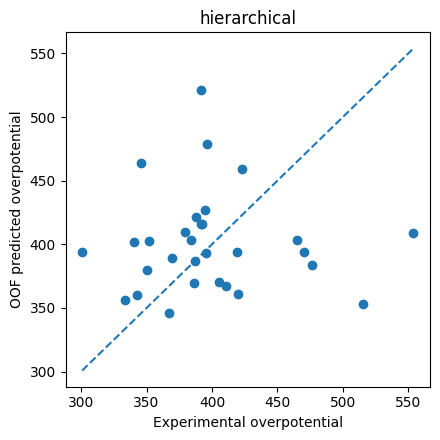

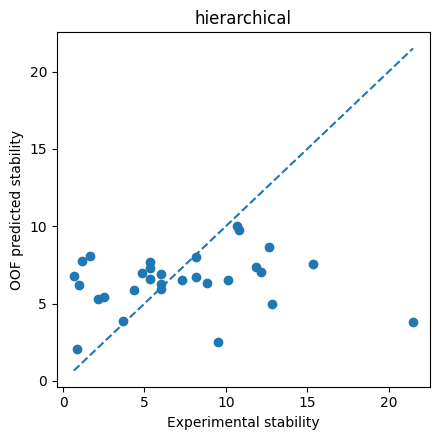

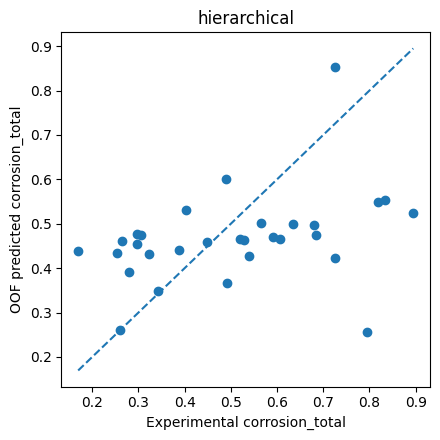

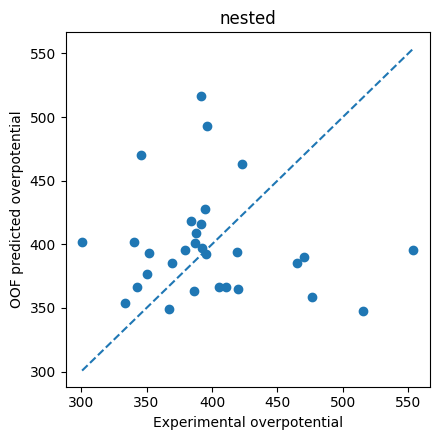

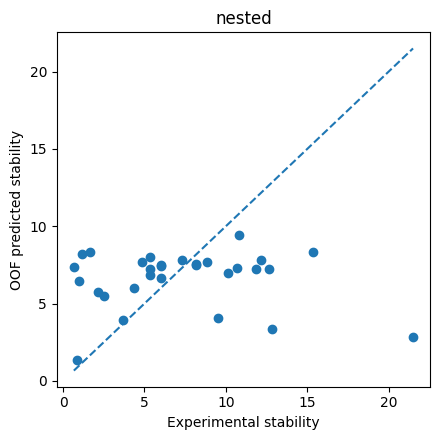

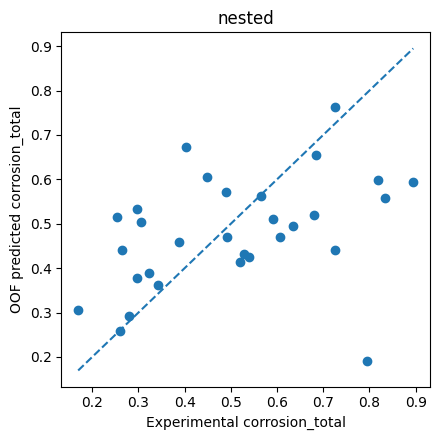

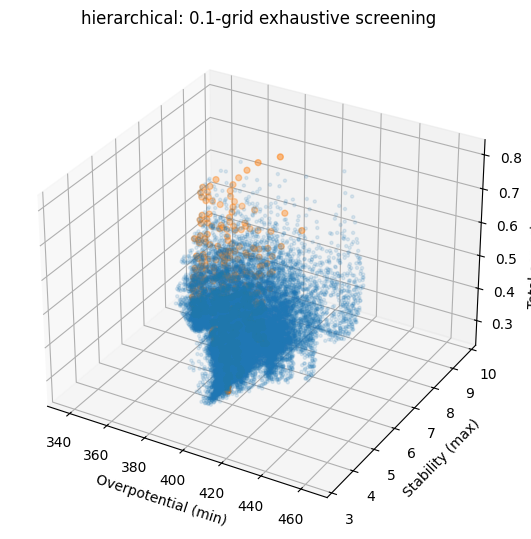

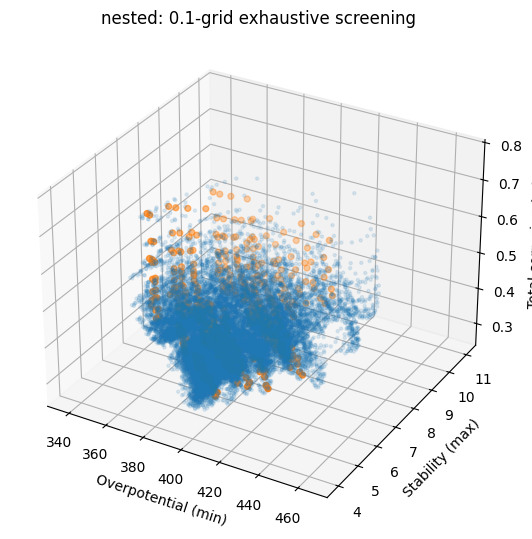

In [ ]:
# ============================================================
# 17. Screening comparison and compact figures
# ============================================================

if RUN_MODE == "compare" and RUN_SCREENING:
    h = SCREEN_RESULTS[False][0]
    n = SCREEN_RESULTS[True][0]
    hset = set(h.loc[h["pareto"], NAME_COL])
    nset = set(n.loc[n["pareto"], NAME_COL])
    union = hset | nset
    inter = hset & nset
    pareto_overlap = {
        "hierarchical_pareto_n": len(hset),
        "nested_pareto_n": len(nset),
        "intersection_n": len(inter),
        "union_n": len(union),
        "jaccard": float(len(inter) / len(union)) if union else np.nan,
    }
    save_json(pareto_overlap, SCREEN_COMPARISON_ROOT / "pareto_overlap.json")
    pd.DataFrame({NAME_COL: sorted(inter)}).to_csv(SCREEN_COMPARISON_ROOT / "pareto_intersection.csv", index=False)
    print("Pareto overlap:", pareto_overlap)

# OOF parity figures
fig_dir = TRAIN_COMPARISON_ROOT / "figures"
fig_dir.mkdir(parents=True, exist_ok=True)
for nested in variants_to_run():
    oof = CV_RESULTS[nested][0]
    vname = variant_name(nested)
    for target in ["overpotential", "stability", "corrosion_total"]:
        x = oof[f"{target}_true"].to_numpy(float)
        y = oof[f"{target}_pred"].to_numpy(float)
        fig, ax = plt.subplots(figsize=(4.5, 4.5))
        ax.scatter(x, y)
        lo = np.nanmin([x.min(), y.min()]); hi = np.nanmax([x.max(), y.max()])
        ax.plot([lo, hi], [lo, hi], linestyle="--")
        ax.set_xlabel(f"Experimental {target}")
        ax.set_ylabel(f"OOF predicted {target}")
        ax.set_title(vname)
        fig.tight_layout()
        fig.savefig(fig_dir / f"{vname}_{target}_oof.png", dpi=200)
        plt.show()

# 3D Pareto scatter for each model variant
if RUN_SCREENING:
    from mpl_toolkits.mplot3d import Axes3D  # noqa: F401
    for nested in variants_to_run():
        pred = SCREEN_RESULTS[nested][0]
        vname = variant_name(nested)
        fig = plt.figure(figsize=(7, 5.5))
        ax = fig.add_subplot(111, projection="3d")
        non = ~pred["pareto"].to_numpy(bool)
        par = pred["pareto"].to_numpy(bool)
        ax.scatter(pred.loc[non, "overpotential_pred"], pred.loc[non, "stability_pred"], pred.loc[non, "corrosion_total_pred"], s=5, alpha=0.12)
        ax.scatter(pred.loc[par, "overpotential_pred"], pred.loc[par, "stability_pred"], pred.loc[par, "corrosion_total_pred"], s=18)
        ax.set_xlabel("Overpotential (min)")
        ax.set_ylabel("Stability (max)")
        ax.set_zlabel("Total corrosion (min)")
        ax.set_title(f"{vname}: 0.1-grid exhaustive screening")
        fig.tight_layout()
        out = SCREEN_ROOT / vname / "figures"
        out.mkdir(parents=True, exist_ok=True)
        fig.savefig(out / "pareto_3d.png", dpi=200)
        plt.show()

In [ ]:
# ============================================================
# 18. Final run manifest / output summary
# ============================================================
manifest = {
    "version": VERSION,
    "config_hash": CONFIG_HASH,
    "run_mode": RUN_MODE,
    "variants": [variant_name(v) for v in variants_to_run()],
    "cv_type": CV_TYPE,
    "inner_cv_type": INNER_CV_TYPE,
    "seeds": SEEDS,
    "nested_clocks": NESTED_CLOCKS,
    "clock_order": list(CLOCK_ORDER),
    "train_csv": TRAIN_CSV_PATH,
    "screen_csv": SCREEN_CSV_PATH,
    "raman_dir": RAMAN_DIR,
    "screen_grid_n": int(len(screen_df)),
    "placeholder_mode": bool(PLACEHOLDER_MODE),
    "notes": [
        "All target and spectroscopy generator checkpoints are saved; inner schedule candidates are saved in checkpoint bundles.",
        "Hierarchical and nested variants have identical predictor architecture; only core/interface/shell update schedules differ.",
        "The shared spectroscopy generator is synchronous and common to both variants, isolating the Nested Learning ablation.",
        "Screening uses only the supplied 0.1-grid candidate table; no RL/generative iterative search is performed.",
        "SEAWATER_screen_cluster.csv is retained as legacy/reference sampling information and is not used by v1 screening.",
    ],
}
save_json(manifest, TRAIN_ROOT / "run_manifest.json")

print("\nSEAWATER v1 completed.")
print("Train root :", TRAIN_ROOT)
print("Screen root:", SCREEN_ROOT)
print("Shared     :", SHARED_ROOT)
print("Nested     :", TRAIN_ROOT / "nested")
print("Hierarchical:", TRAIN_ROOT / "hierarchical")
print("Comparison :", TRAIN_COMPARISON_ROOT)
if PLACEHOLDER_MODE:
    print("\nWARNING: PLACEHOLDER_MODE=True. Do not interpret scientific performance until the placeholder values are replaced and PLACEHOLDER_MODE=False.")


SEAWATER v1 completed.
Train root : /content/drive/MyDrive/Colab Notebooks/SEAWATER/train/v1
Screen root: /content/drive/MyDrive/Colab Notebooks/SEAWATER/screen/v1
Shared     : /content/drive/MyDrive/Colab Notebooks/SEAWATER/train/v1/shared
Nested     : /content/drive/MyDrive/Colab Notebooks/SEAWATER/train/v1/nested
Hierarchical: /content/drive/MyDrive/Colab Notebooks/SEAWATER/train/v1/hierarchical
Comparison : /content/drive/MyDrive/Colab Notebooks/SEAWATER/train/v1/comparison
